<a href="https://colab.research.google.com/github/NathaliaVega01/TrabajoIntegrador-MercadoMotocicletasColombia/blob/main/TrabajoIntegrador_ModeloMercadoMotocicletas_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Modelación y pronóstico del mercado de motocicletas en Colombia con base en variables macroeconómicas**

Nathalia Vega Aguirre

##Entendimiento del Problema



##Entendimiento de los Datos



In [1]:
#Se importan las librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats
import math


In [2]:
#Dataset Trimestral
df_datamarket_trim = pd.read_excel("Data - Mercado.xlsx", sheet_name="DataTrimestral")

#Dataset Mensual
df_datamarket_men = pd.read_excel("Data - Mercado.xlsx", sheet_name="DataMensual")

In [3]:
df_datamarket_trim.head()

,Periodo,FechaInicio,FechaFin,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,PIB,...,DTF,InflacionAnual,InflacionTrimestral,DiasHabiles,Remesas,PIB_PC,SMMLV,ICC,IEC,ICE
0,2005 - Trim 1,2005-01-01,2005-03-01,37999,40356.925000,16083.864000,2497.111000,0.569730,0.134391,126088.657004,...,0.074733,0.0503,0.026326,72,731.13,312.433757,426000,0.142667,0.194333,0.065333
1,2005 - Trim 2,2005-04-01,2005-06-01,46544,40472.751667,16344.090000,2233.020667,0.576303,0.120203,128906.474678,...,0.072167,0.0483,0.012552,75,803.26,318.501879,426000,0.153667,0.175667,0.120000
2,2005 - Trim 3,2005-07-01,2005-09-01,62445,40590.071000,16573.203667,2196.234667,0.581704,0.117011,128717.054381,...,0.069767,0.0502,0.004802,76,851.47,317.114632,426000,0.229333,0.273667,0.162333
3,2005 - Trim 4,2005-10-01,2005-12-01,65080,40711.004667,17130.671000,1935.233000,0.598455,0.101502,131260.139968,...,0.063900,0.0485,0.004105,75,927.86,322.419309,426000,0.200333,0.224000,0.164000
4,2006 - Trim 1,2006-01-01,2006-03-01,86446,40831.239333,16551.336333,2386.386667,0.575535,0.126012,134044.350100,...,0.060400,0.0411,0.019120,75,855.89,328.288713,455700,0.272667,0.306667,0.222000


In [4]:
df_datamarket_men.head()

,Fecha,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,TRM,Var.TRM,TasaInteres,DTF,InflacionAnual,InflacionMensual,DiasHabiles,SMMLV,ICC,IEC,ICE
0,2005-01-01,11666,40318.940,16059.539,2455.597,0.569725,0.132626,2362.96,NaN,0.065,0.0767,0.0543,0.0082,24,426000,0.193,0.266,0.083
1,2005-02-01,12543,40358.098,16023.387,2629.476,0.567561,0.140969,2340.49,-0.009509,0.065,0.0741,0.0525,0.0102,24,426000,0.139,0.189,0.065
2,2005-03-01,13790,40393.737,16168.666,2406.260,0.571899,0.129543,2353.71,0.005648,0.065,0.0734,0.0503,0.0077,24,426000,0.096,0.128,0.048
3,2005-04-01,13569,40433.355,16346.018,2233.329,0.577268,0.120205,2350.01,-0.001572,0.065,0.0729,0.0501,0.0044,26,426000,0.133,0.169,0.080
4,2005-05-01,15241,40472.262,16375.551,2337.372,0.577425,0.124907,2339.22,-0.004591,0.065,0.0718,0.0504,0.0041,24,426000,0.141,0.147,0.130


In [5]:
df_datamarket_trim.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 86 entries, 0 to 85
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Periodo              86 non-null     object        
 1   FechaInicio          86 non-null     datetime64[ns]
 2   FechaFin             86 non-null     datetime64[ns]
 3   Registros            86 non-null     int64         
 4   PoblacionTotal       86 non-null     float64       
 5   PoblacionOcupada     86 non-null     float64       
 6   PoblacionDesocupada  86 non-null     float64       
 7   TasaOcupacion        86 non-null     float64       
 8   TasaDesocupacion     86 non-null     float64       
 9   PIB                  86 non-null     float64       
 10  Var.PIB              85 non-null     float64       
 11  Exportaciones        86 non-null     float64       
 12  Importaciones        86 non-null     float64       
 13  TRM                  86 non-null     

In [6]:
df_datamarket_men.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 259 entries, 0 to 258
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Fecha                259 non-null    datetime64[ns]
 1   Registros            259 non-null    int64         
 2   PoblacionTotal       259 non-null    float64       
 3   PoblacionOcupada     259 non-null    float64       
 4   PoblacionDesocupada  259 non-null    float64       
 5   TasaOcupacion        259 non-null    float64       
 6   TasaDesocupacion     259 non-null    float64       
 7   TRM                  259 non-null    float64       
 8   Var.TRM              258 non-null    float64       
 9   TasaInteres          259 non-null    float64       
 10  DTF                  259 non-null    float64       
 11  InflacionAnual       259 non-null    float64       
 12  InflacionMensual     259 non-null    float64       
 13  DiasHabiles          259 non-null  

In [7]:
df_datamarket_trim.describe()

,FechaInicio,FechaFin,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,PIB,Var.PIB,...,DTF,InflacionAnual,InflacionTrimestral,DiasHabiles,Remesas,PIB_PC,SMMLV,ICC,IEC,ICE
count,86,86,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,85.000000,...,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,8.600000e+01,86.000000,86.000000,86.000000
mean,2015-08-16 15:20:55.813953536,2015-10-16 10:19:32.093023232,147814.290698,46050.282643,20057.032176,2459.795443,0.582132,0.109970,195860.249919,0.008961,...,0.063464,0.049278,0.012294,74.046512,1596.101628,421.482222,8.463711e+05,0.053163,0.099310,-0.016140
min,2005-01-01 00:00:00,2005-03-01 00:00:00,37999.000000,40356.925000,16018.596000,1896.889333,0.445454,0.077353,126088.657004,-0.161649,...,0.018300,0.015100,-0.005399,71.000000,731.130000,312.433757,4.260000e+05,-0.361333,-0.221667,-0.666667
25%,2010-04-23 18:00:00,2010-06-24 00:00:00,110789.250000,42852.866417,18501.452000,2162.569667,0.568585,0.095849,159262.015271,0.003524,...,0.043667,0.032000,0.004829,73.000000,1012.065000,371.378539,5.765000e+05,-0.097583,-0.050250,-0.173500
50%,2015-08-16 00:00:00,2015-10-16 12:00:00,144852.000000,45463.270000,20440.724000,2389.613803,0.583342,0.108060,200982.445123,0.008429,...,0.054233,0.044500,0.010534,74.000000,1280.355000,437.484155,7.183500e+05,0.057167,0.105833,-0.004833
75%,2020-12-09 00:00:00,2021-02-06 12:00:00,168117.000000,49670.540083,21423.044667,2581.138750,0.601005,0.118152,221924.415912,0.014502,...,0.087033,0.058025,0.016639,75.000000,1941.225000,456.382773,1.006399e+06,0.226750,0.245000,0.165750
max,2026-04-01 00:00:00,2026-06-01 00:00:00,332084.000000,52505.805000,24439.674599,4446.712000,0.628518,0.209399,262061.541560,0.098772,...,0.138700,0.133400,0.045560,77.000000,3354.000000,499.109654,2.000000e+06,0.345333,0.425667,0.368667
std,NaN,NaN,57452.787958,3755.446772,2272.149409,456.913499,0.029608,0.020973,38848.960867,0.024685,...,0.028272,0.025981,0.010360,1.396693,746.823424,52.396239,3.691941e+05,0.184324,0.161864,0.238429


In [8]:
df_datamarket_men.describe()

,Fecha,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,TRM,Var.TRM,TasaInteres,DTF,InflacionAnual,InflacionMensual,DiasHabiles,SMMLV,ICC,IEC,ICE
count,259,259.000000,259.000000,259.000000,259.000000,259.000000,259.000000,259.000000,258.000000,259.000000,259.000000,259.000000,259.000000,259.000000,2.590000e+02,259.000000,259.000000,259.000000
mean,2015-10-01 08:48:11.119691008,49591.223938,46075.511853,20074.367501,2458.656754,0.582181,0.109875,2850.731004,0.001809,0.062674,0.063613,0.049357,0.004062,24.675676,8.508252e+05,0.053757,0.100097,-0.015830
min,2005-01-01 00:00:00,202.000000,40318.940000,15572.558000,1763.467000,0.424971,0.070249,1712.280000,-0.071816,0.017500,0.017600,0.014900,-0.003800,22.000000,4.260000e+05,-0.413000,-0.283000,-0.730000
25%,2010-05-16 12:00:00,37747.500000,42844.232500,18363.613000,2142.199131,0.568686,0.094752,1979.395000,-0.016732,0.041250,0.044050,0.031750,0.001350,24.000000,5.765000e+05,-0.105000,-0.048000,-0.172000
50%,2015-10-01 00:00:00,47251.000000,45482.981000,20384.009000,2349.787000,0.585916,0.107484,2860.000000,-0.002518,0.052500,0.054500,0.044200,0.003200,25.000000,7.183500e+05,0.067000,0.112000,0.007000
75%,2021-02-15 00:00:00,56877.500000,49739.386000,21535.027000,2632.811500,0.601032,0.119876,3693.000000,0.018021,0.092500,0.086650,0.058650,0.006050,25.000000,1.014980e+06,0.221000,0.252000,0.176000
max,2026-07-01 00:00:00,132098.000000,52584.648000,24598.644740,4695.063000,0.640080,0.219720,4922.300000,0.135486,0.132500,0.143900,0.133400,0.017800,27.000000,2.000000e+06,0.388000,0.488000,0.408000
std,NaN,20168.983131,3755.770311,2289.872066,473.955877,0.030279,0.021839,887.069221,0.033475,0.030890,0.028307,0.025801,0.003844,0.970009,3.739757e+05,0.187433,0.167623,0.240276


###Análisis Exploratorio de Datos

####Variable Objetivo: Registros (Unidades de Motocicletas - Mercado)

In [9]:
objetivo = df_datamarket_men[["Fecha", "Registros"]].copy()

# Resumen de calidad
print("Total de observaciones:", len(objetivo))
print("Valores faltantes:", objetivo["Registros"].isna().sum())
print("Valores iguales a cero:", (objetivo["Registros"] == 0).sum())
print("Valores negativos:", (objetivo["Registros"] < 0).sum())

# Identificar posibles meses faltantes
calendario = pd.date_range(
    start=objetivo["Fecha"].min().to_period("M").to_timestamp(),
    end=objetivo["Fecha"].max().to_period("M").to_timestamp(),
    freq="MS"
)

fechas_observadas = pd.DatetimeIndex(
    objetivo["Fecha"].dt.to_period("M").drop_duplicates()
                       .dt.to_timestamp()
)

meses_faltantes = calendario.difference(fechas_observadas)

Total de observaciones: 259
Valores faltantes: 0
Valores iguales a cero: 0
Valores negativos: 0


In [10]:
estadisticos = objetivo["Registros"].describe().to_frame().T

estadisticos["mediana"] = objetivo["Registros"].median()
estadisticos["asimetria"] = objetivo["Registros"].skew()
estadisticos["curtosis"] = objetivo["Registros"].kurtosis()
estadisticos["coef_variacion_pct"] = (
    objetivo["Registros"].std()
    / objetivo["Registros"].mean()
) * 100

display(estadisticos.round(2))

,count,mean,std,min,25%,50%,75%,max,mediana,asimetria,curtosis,coef_variacion_pct
Registros,259.0,49591.22,20168.98,202.0,37747.5,47251.0,56877.5,132098.0,47251.0,1.09,2.44,40.67


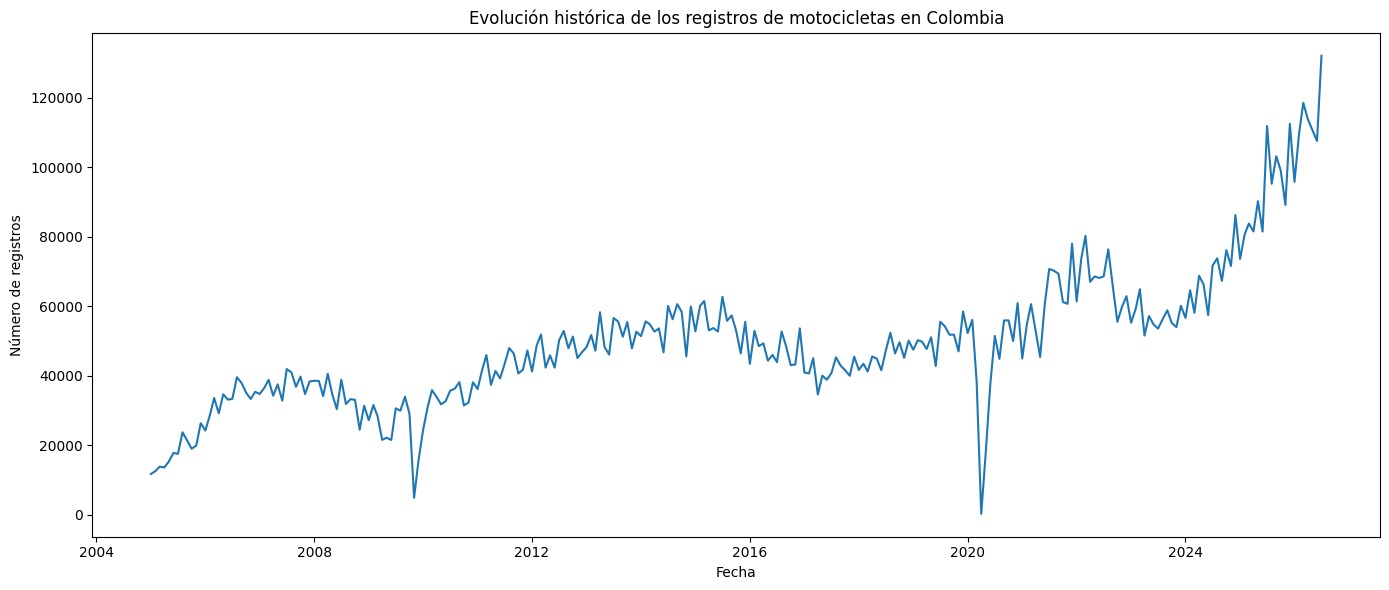

In [11]:
plt.figure(figsize=(14, 6))

plt.plot(
    objetivo["Fecha"],
    objetivo["Registros"],
    linewidth=1.5
)

plt.title("Evolución histórica de los registros de motocicletas en Colombia")
plt.xlabel("Fecha")
plt.ylabel("Número de registros")
plt.tight_layout()
plt.show()

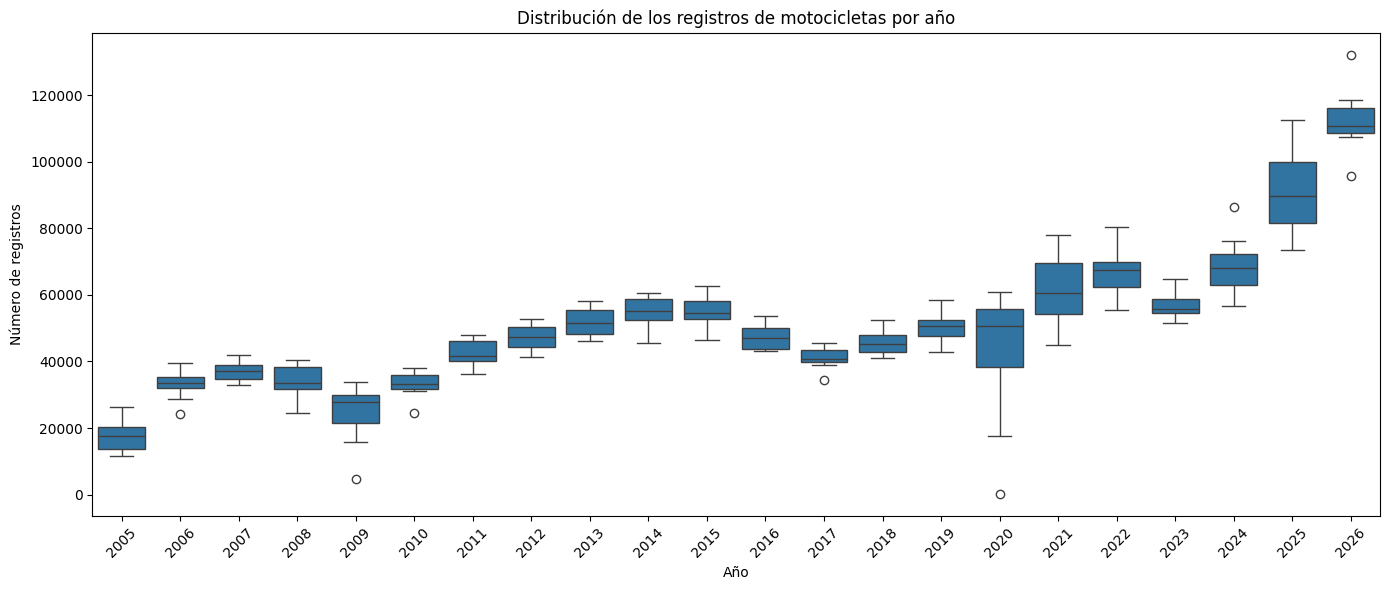

In [12]:
# Extraer el año de la fecha
objetivo["Año"] = objetivo["Fecha"].dt.year

# Distribución de registros por año
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=objetivo,
    x="Año",
    y="Registros"
)

plt.title("Distribución de los registros de motocicletas por año")
plt.xlabel("Año")
plt.ylabel("Número de registros")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

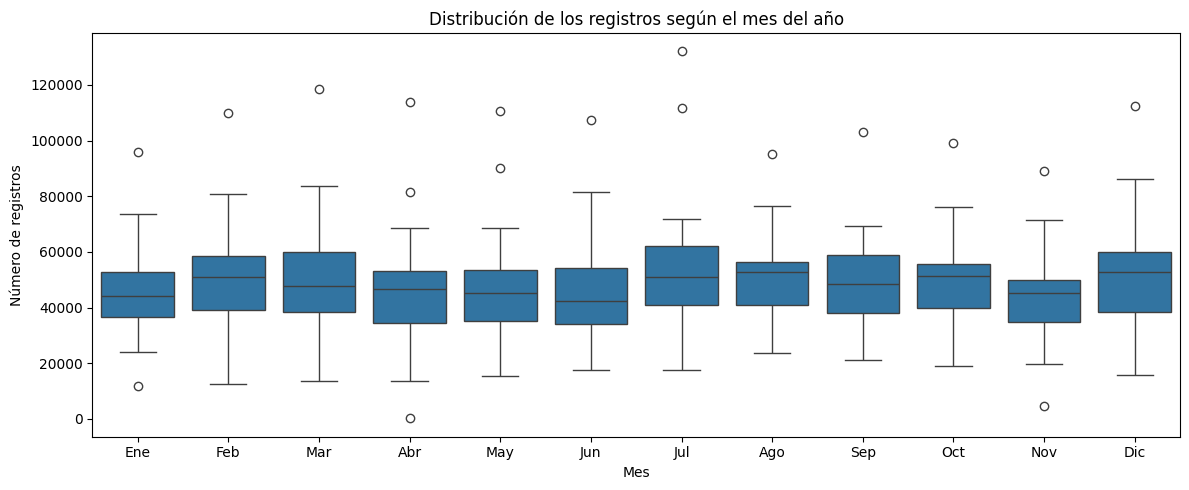

In [13]:
objetivo["Mes"] = objetivo["Fecha"].dt.month

nombres_meses = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
]

# Distribución de registros por mes calendario
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=objetivo,
    x="Mes",
    y="Registros"
)

plt.xticks(range(12), nombres_meses)
plt.title("Distribución de los registros según el mes del año")
plt.xlabel("Mes")
plt.ylabel("Número de registros")
plt.tight_layout()
plt.show()

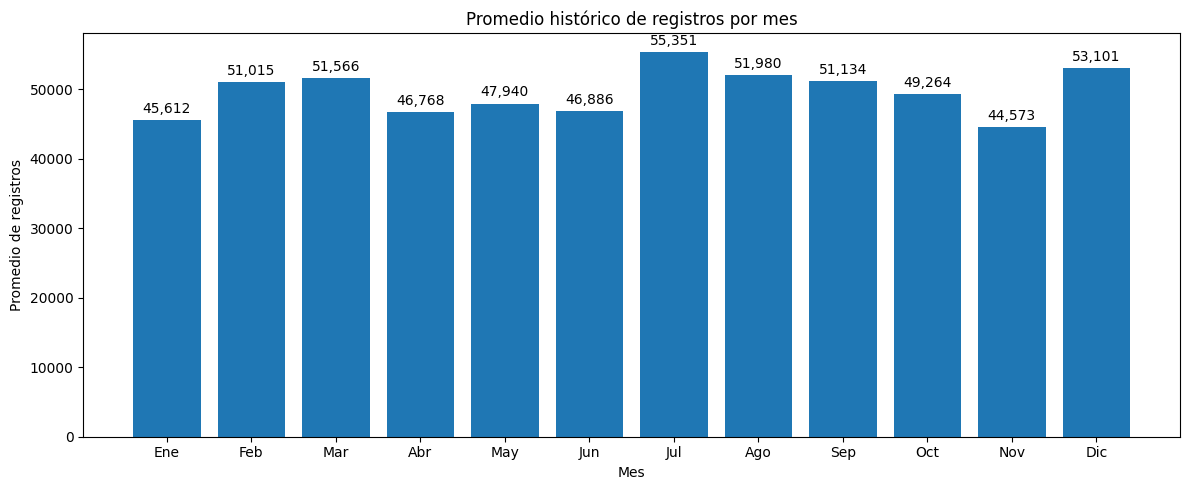

In [14]:
promedio_mensual = (
    objetivo.groupby("Mes")["Registros"]
    .mean()
    .reindex(range(1, 13))
)

plt.figure(figsize=(12, 5))

barras = plt.bar(nombres_meses, promedio_mensual.values)

# Mostrar etiquetas en cada barra
plt.bar_label(
    barras,
    labels=[f"{valor:,.0f}" for valor in promedio_mensual.values],
    padding=3
)

plt.title("Promedio histórico de registros por mes")
plt.xlabel("Mes")
plt.ylabel("Promedio de registros")
plt.tight_layout()
plt.show()

In [15]:
objetivo = objetivo.sort_values("Fecha").copy()

# Variación absoluta mensual
objetivo["Cambio_mensual"] = objetivo["Registros"].diff()

# Variación porcentual mensual
objetivo["Variacion_mensual_pct"] = (
    objetivo["Registros"].pct_change(fill_method=None) * 100
)

# Variación interanual: mismo mes del año anterior
objetivo["Variacion_interanual_pct"] = (
    objetivo["Registros"].pct_change(periods=12, fill_method=None) * 100
)

# Mostrar resultados
display(objetivo)

,Fecha,Registros,Año,Mes,Cambio_mensual,Variacion_mensual_pct,Variacion_interanual_pct
0,2005-01-01,11666,2005,1,NaN,NaN,NaN
1,2005-02-01,12543,2005,2,877.0,7.517572,NaN
2,2005-03-01,13790,2005,3,1247.0,9.941800,NaN
3,2005-04-01,13569,2005,4,-221.0,-1.602611,NaN
4,2005-05-01,15241,2005,5,1672.0,12.322205,NaN
...,...,...,...,...,...,...,...
254,2026-03-01,118548,2026,3,8771.0,7.989834,41.512677
255,2026-04-01,113779,2026,4,-4769.0,-4.022843,39.590720
256,2026-05-01,110748,2026,5,-3031.0,-2.663936,22.764156
257,2026-06-01,107557,2026,6,-3191.0,-2.881316,32.009033


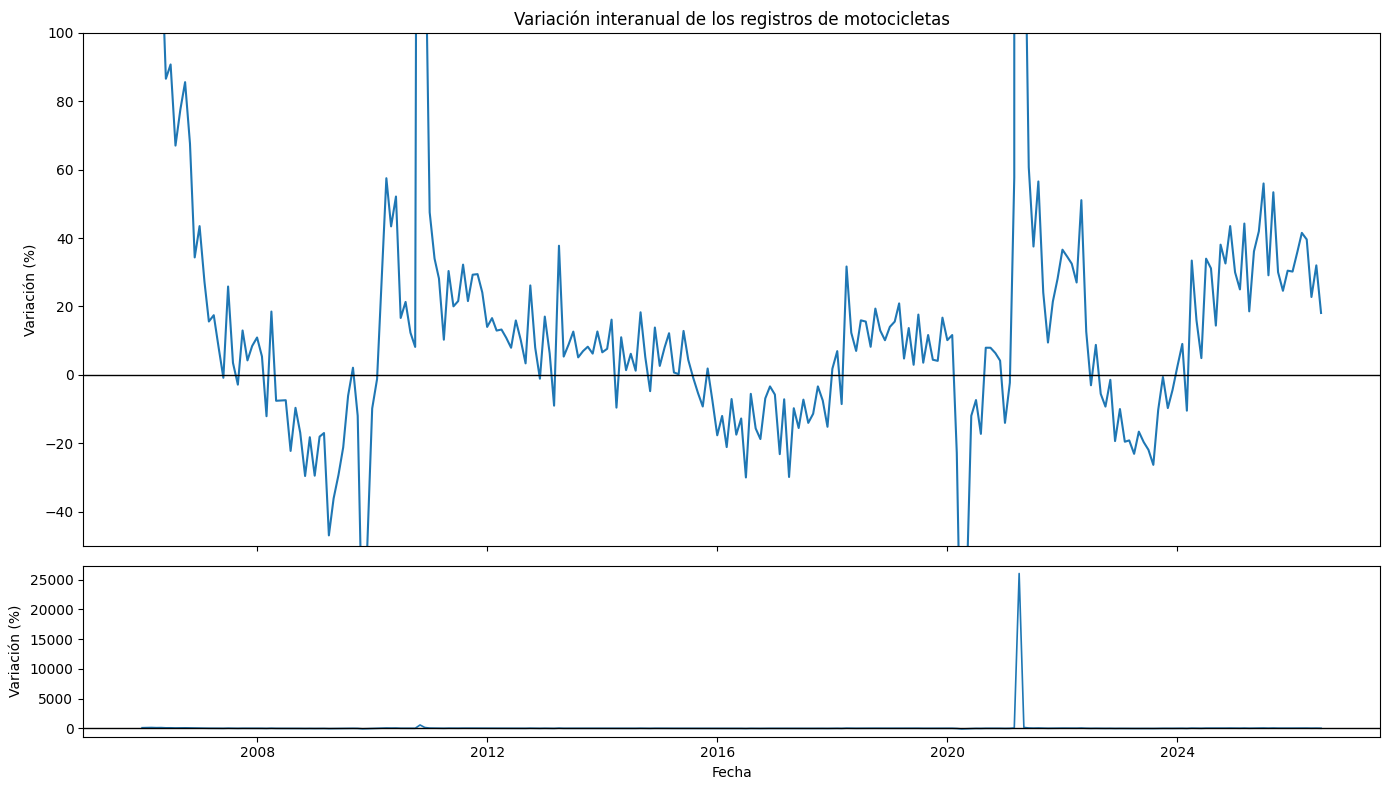

In [16]:
fig, ax = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)

# Gráfico principal: comportamiento habitual
ax[0].plot(
    objetivo["Fecha"],
    objetivo["Variacion_interanual_pct"],
    linewidth=1.5
)
ax[0].axhline(0, color="black", linewidth=1)
ax[0].set_ylim(-50, 100)
ax[0].set_title("Variación interanual de los registros de motocicletas")
ax[0].set_ylabel("Variación (%)")

# Gráfico inferior: serie completa
ax[1].plot(
    objetivo["Fecha"],
    objetivo["Variacion_interanual_pct"],
    linewidth=1.2
)
ax[1].axhline(0, color="black", linewidth=1)
ax[1].set_ylabel("Variación (%)")
ax[1].set_xlabel("Fecha")

plt.tight_layout()
plt.show()

In [17]:
serie = objetivo["Registros"].dropna()

q1 = serie.quantile(0.25)
q3 = serie.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

atipicos = objetivo[
    (objetivo["Registros"] < limite_inferior) |
    (objetivo["Registros"] > limite_superior)
]

display(atipicos[["Fecha", "Registros"]])

print("Cantidad de posibles valores atípicos:", len(atipicos))

,Fecha,Registros
58,2009-11-01,4813
183,2020-04-01,202
239,2024-12-01,86239
244,2025-05-01,90212
246,2025-07-01,111861
247,2025-08-01,95242
248,2025-09-01,103166
249,2025-10-01,98990
250,2025-11-01,89130
251,2025-12-01,112509


Cantidad de posibles valores atípicos: 17


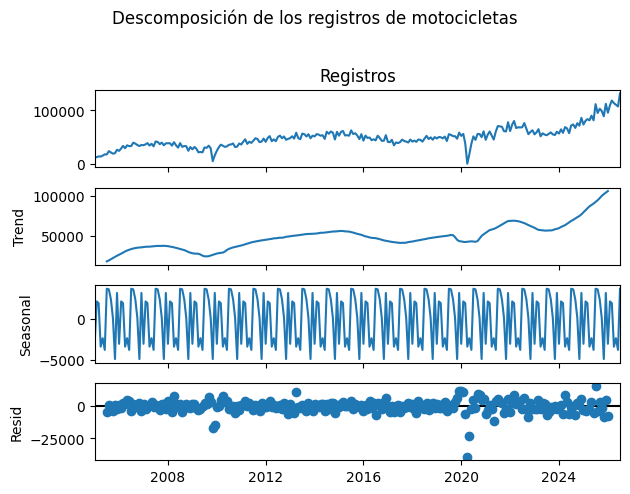

In [18]:
from statsmodels.tsa.seasonal import seasonal_decompose

# La descomposición requiere una serie mensual regular y sin faltantes.
serie_mensual = (
    df_datamarket_men.set_index("Fecha")["Registros"]
      .groupby(lambda x: x.to_period("M"))
      .sum(min_count=1)
)

serie_mensual.index = serie_mensual.index.to_timestamp()

# Comprobar continuidad y valores faltantes antes de continuar
serie_mensual = serie_mensual.asfreq("MS")

if serie_mensual.isna().any():
    print("Hay meses faltantes. Investiga y resuelve esos faltantes antes de descomponer.")
elif len(serie_mensual) < 24:
    print("Se recomienda contar con al menos dos ciclos anuales completos.")
else:
    descomposicion = seasonal_decompose(
        serie_mensual,
        model="additive",
        period=12
    )

    descomposicion.plot()
    plt.suptitle("Descomposición de los registros de motocicletas", y=1.02)
    plt.tight_layout()
    plt.show()

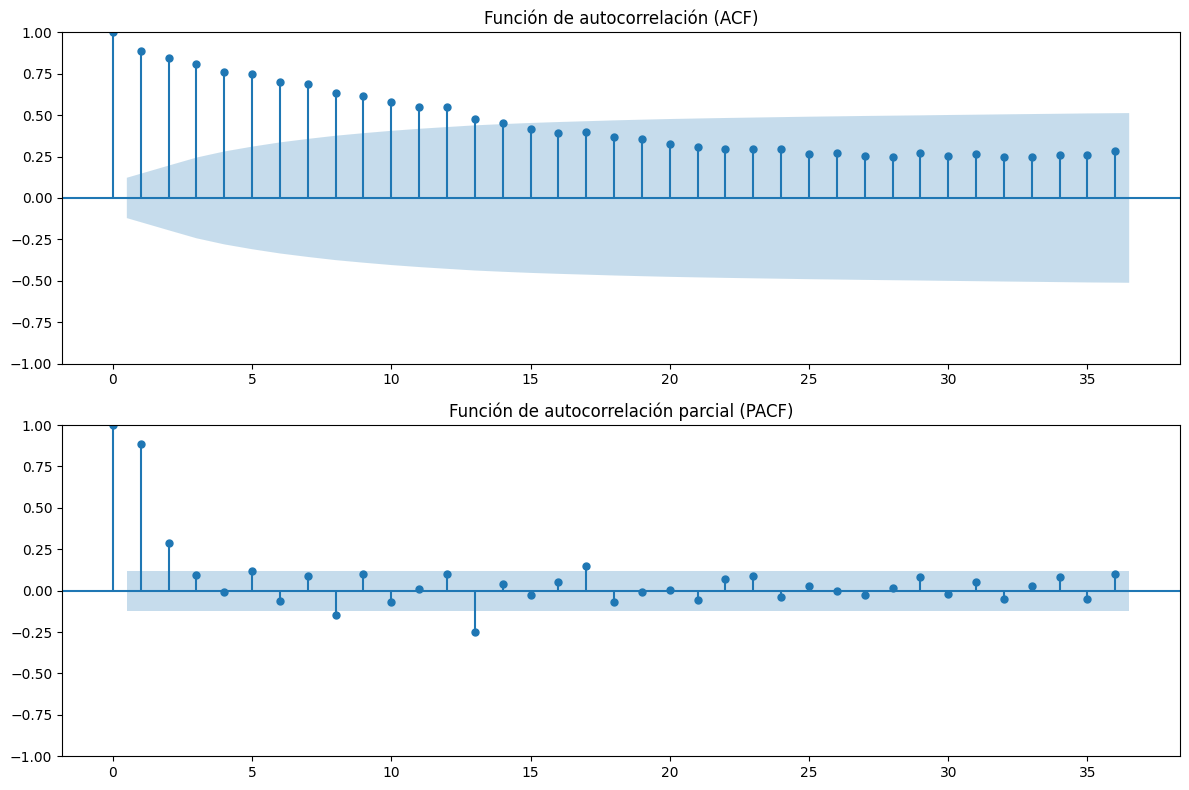

In [19]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Ejecutar solo con una serie mensual regular y sin faltantes
if serie_mensual.isna().any():
    print("Completa la revisión de faltantes antes de calcular ACF y PACF.")
else:
    fig, axes = plt.subplots(2, 1, figsize=(12, 8))

    plot_acf(
        serie_mensual,
        lags=min(36, len(serie_mensual) // 2 - 1),
        ax=axes[0]
    )
    axes[0].set_title("Función de autocorrelación (ACF)")

    plot_pacf(
        serie_mensual,
        lags=min(36, len(serie_mensual) // 2 - 1),
        method="ywm",
        ax=axes[1]
    )
    axes[1].set_title("Función de autocorrelación parcial (PACF)")

    plt.tight_layout()
    plt.show()

####Variables Predictoras: Variables Macroeconómicas

#####Variables: Periodicidad Mensual

In [20]:
variables_predictoras = [
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "TasaDesocupacion",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "DTF",
    "InflacionAnual",
    "InflacionMensual",
    "DiasHabiles",
    "SMMLV",
    "ICC",
    "IEC",
    "ICE"
]

# Conservar únicamente las columnas que existan en la base
variables_predictoras = [
    col for col in variables_predictoras
    if col in df_datamarket_men.columns
]

predictores = df_datamarket_men[variables_predictoras].copy()

for col in variables_predictoras:
    predictores[col] = pd.to_numeric(
        predictores[col], errors="coerce"
    )

inventario = pd.DataFrame({
    "No_nulos": predictores.notna().sum(),
    "Faltantes": predictores.isna().sum(),
    "Porcentaje_faltantes": predictores.isna().mean() * 100,
    "Valores_unicos": predictores.nunique()
})

display(inventario.round(2))

,No_nulos,Faltantes,Porcentaje_faltantes,Valores_unicos
PoblacionTotal,259,0,0.00,259
PoblacionOcupada,259,0,0.00,259
PoblacionDesocupada,259,0,0.00,259
TasaOcupacion,259,0,0.00,259
TasaDesocupacion,259,0,0.00,257
TRM,259,0,0.00,257
Var.TRM,258,1,0.39,258
TasaInteres,259,0,0.00,43
DTF,259,0,0.00,213
InflacionAnual,259,0,0.00,218


In [21]:
display(predictores.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
PoblacionTotal,259.0,46075.512,3755.770,40318.940,42844.232,45482.981,49739.386,52584.648
PoblacionOcupada,259.0,20074.368,2289.872,15572.558,18363.613,20384.009,21535.027,24598.645
PoblacionDesocupada,259.0,2458.657,473.956,1763.467,2142.199,2349.787,2632.812,4695.063
TasaOcupacion,259.0,0.582,0.030,0.425,0.569,0.586,0.601,0.640
TasaDesocupacion,259.0,0.110,0.022,0.070,0.095,0.107,0.120,0.220
TRM,259.0,2850.731,887.069,1712.280,1979.395,2860.000,3693.000,4922.300
Var.TRM,258.0,0.002,0.033,-0.072,-0.017,-0.003,0.018,0.135
TasaInteres,259.0,0.063,0.031,0.018,0.041,0.052,0.092,0.132
DTF,259.0,0.064,0.028,0.018,0.044,0.054,0.087,0.144
InflacionAnual,259.0,0.049,0.026,0.015,0.032,0.044,0.059,0.133


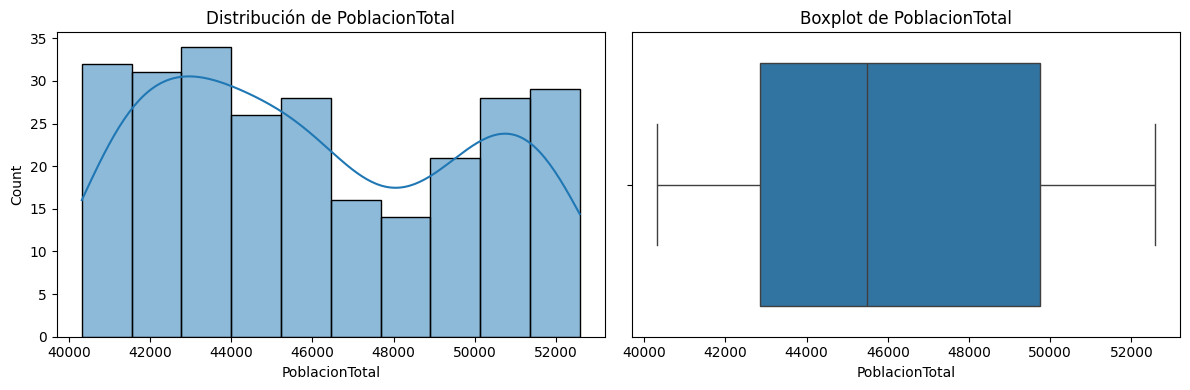

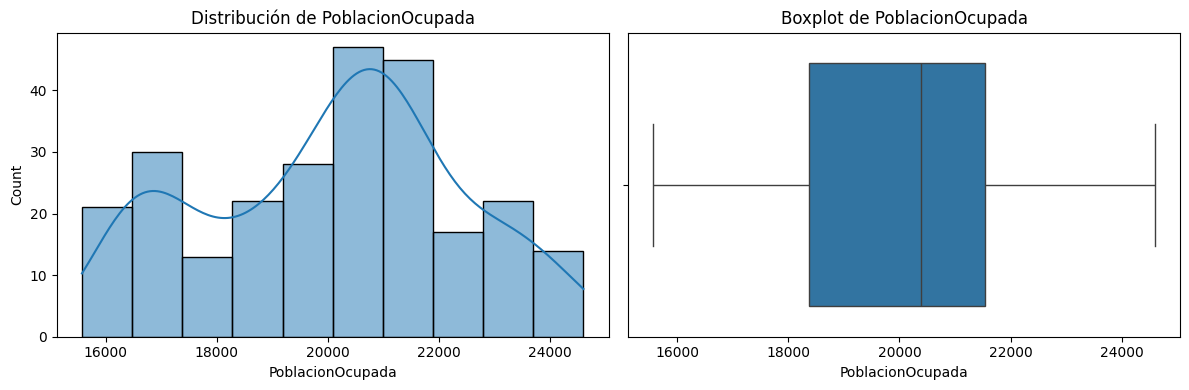

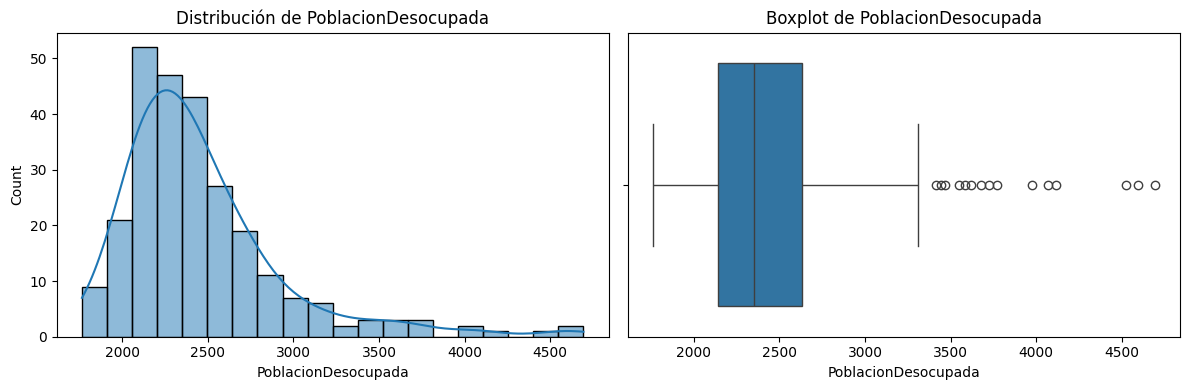

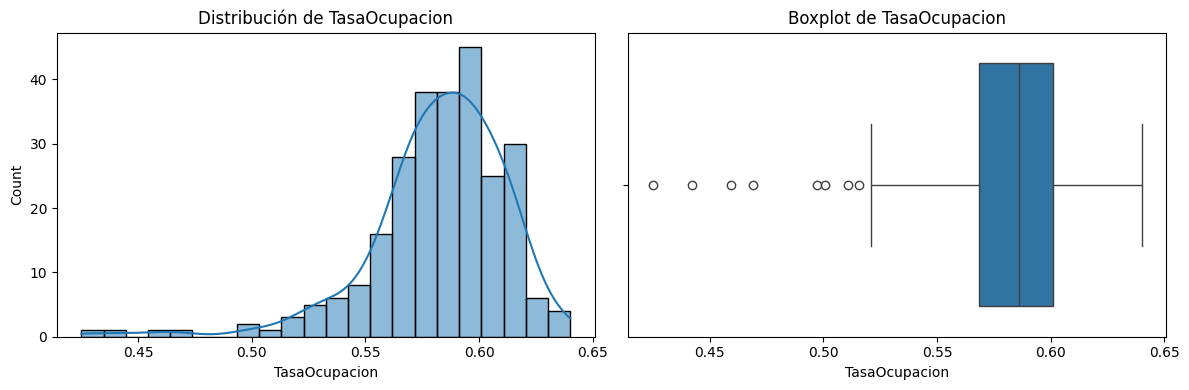

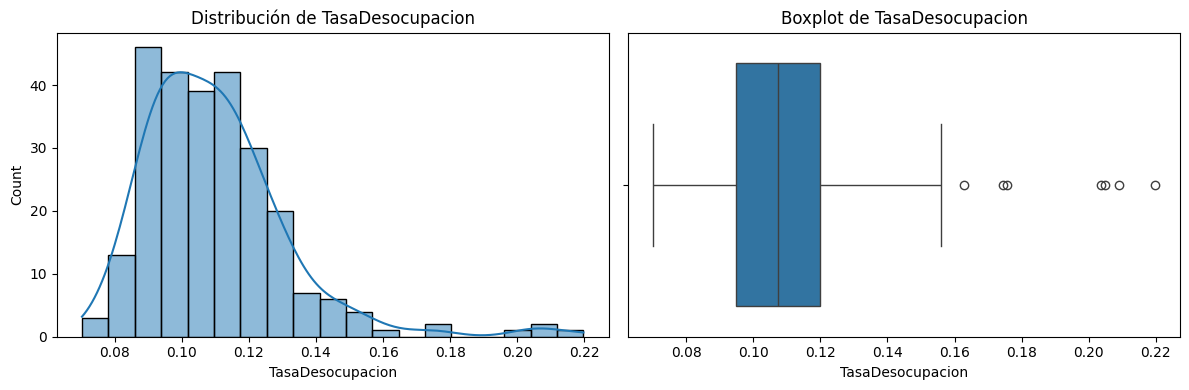

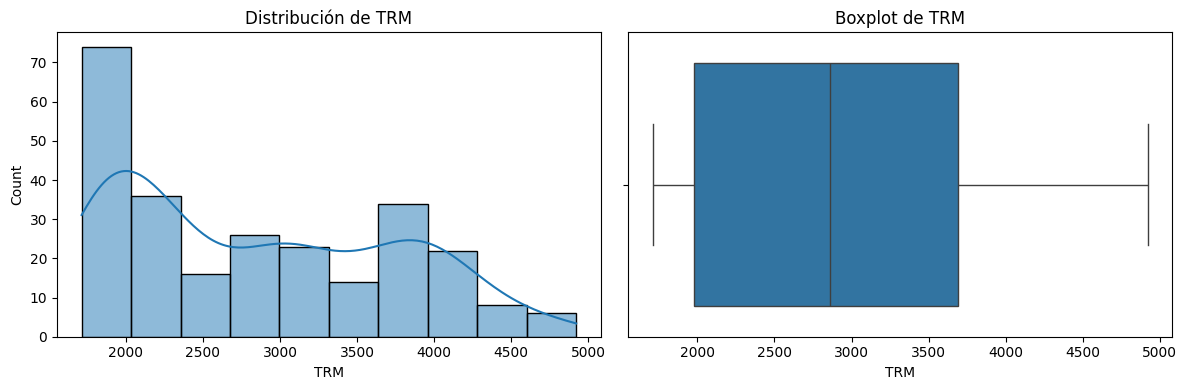

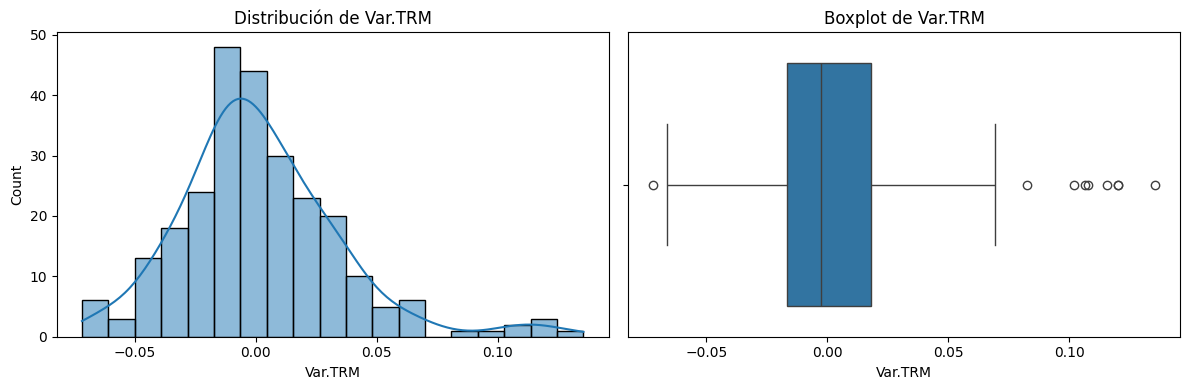

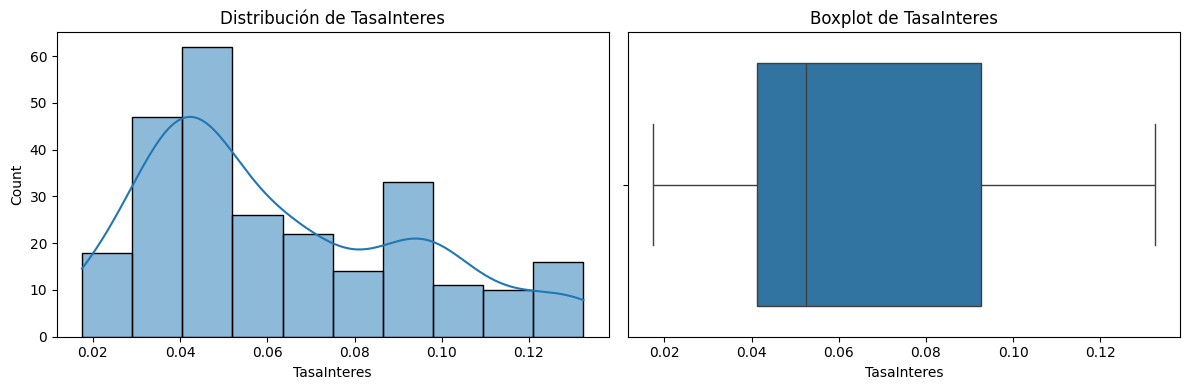

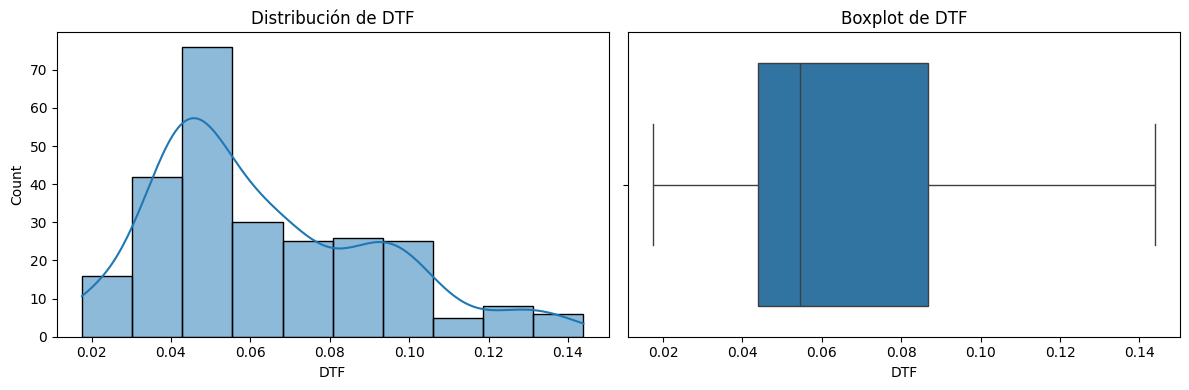

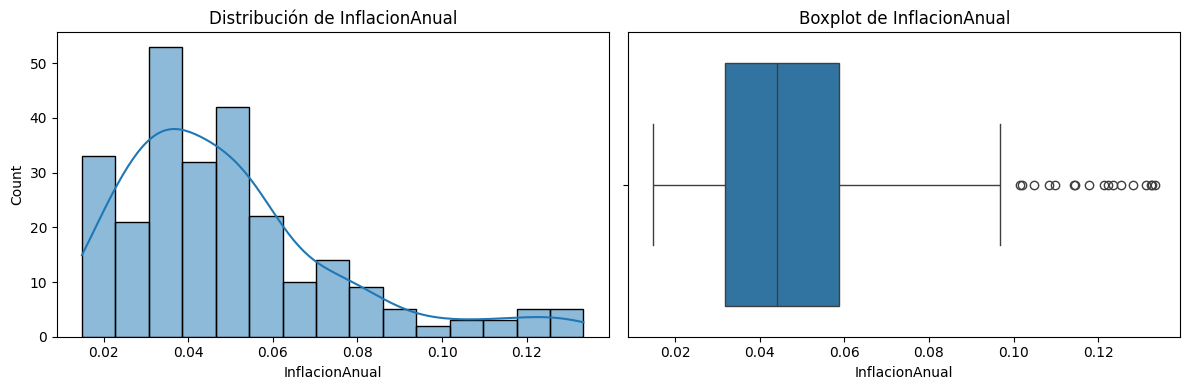

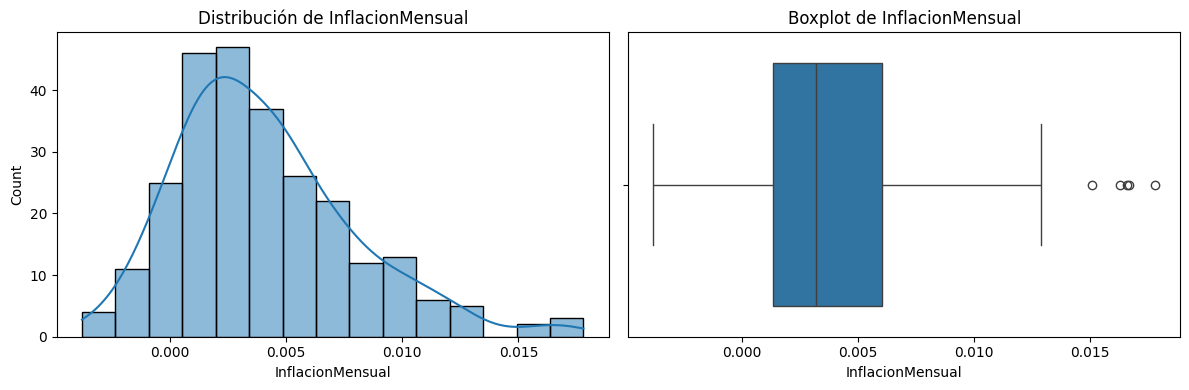

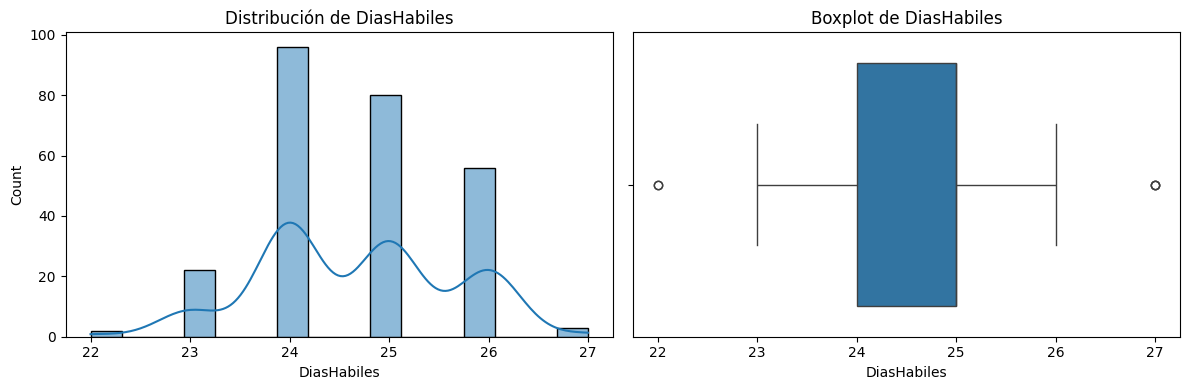

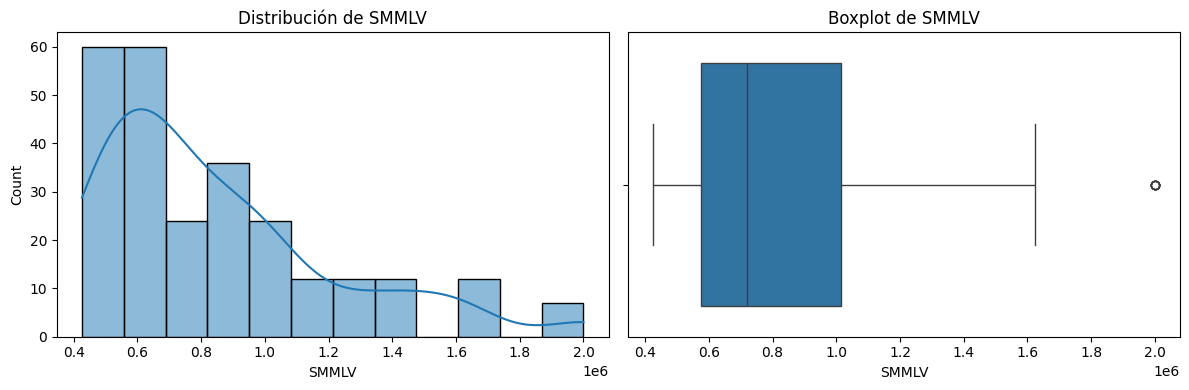

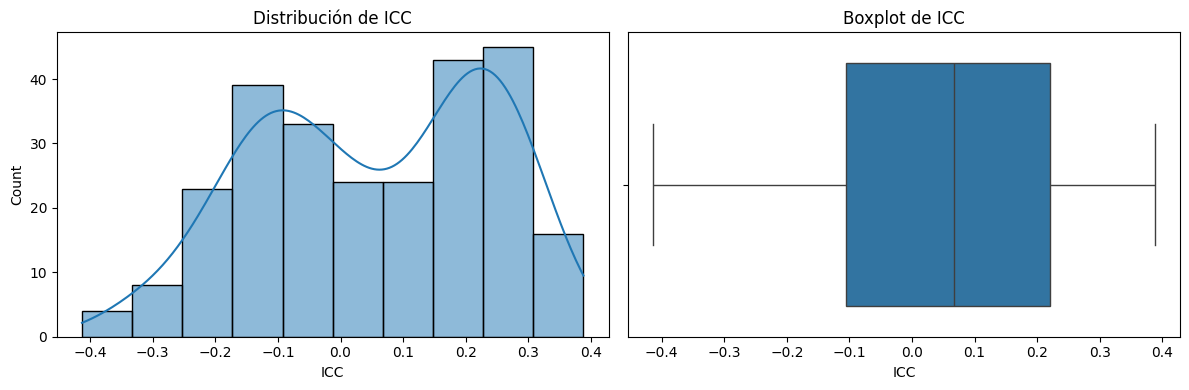

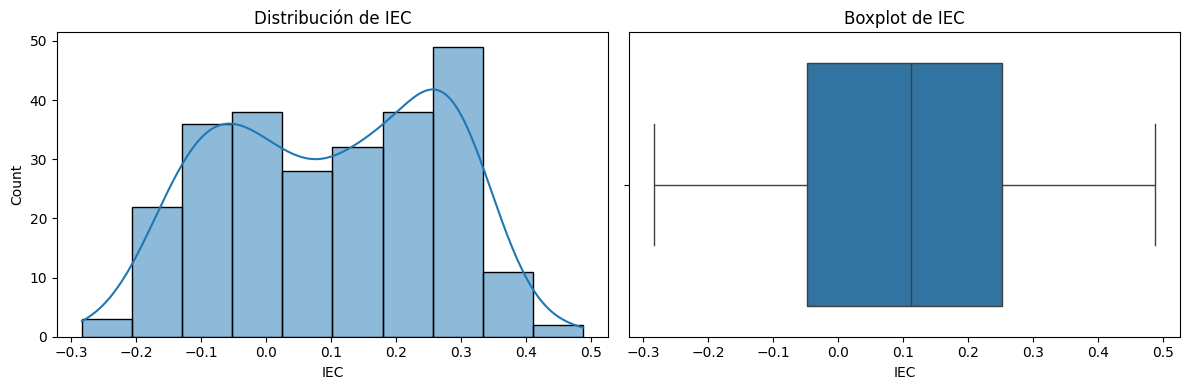

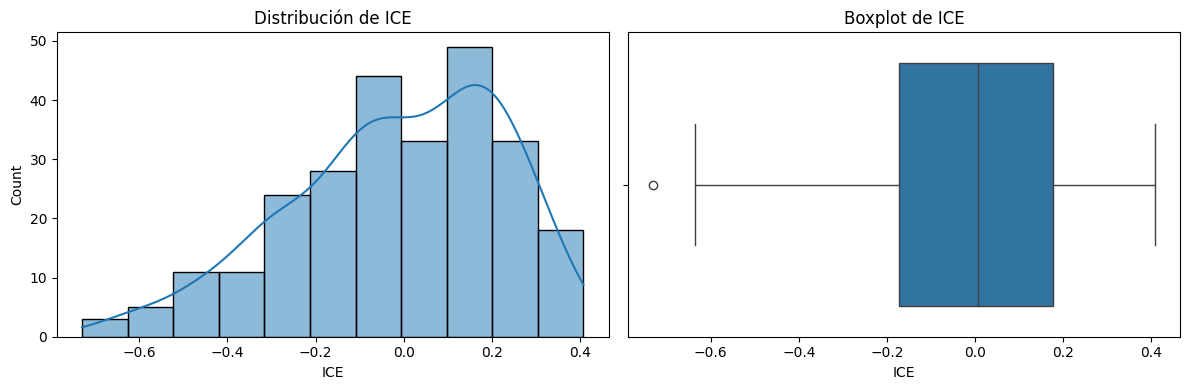

In [22]:
for col in variables_predictoras:

    datos = predictores[col].dropna()

    if datos.empty:
        continue

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(datos, kde=True, ax=axes[0])
    axes[0].set_title(f"Distribución de {col}")

    sns.boxplot(x=datos, ax=axes[1])
    axes[1].set_title(f"Boxplot de {col}")

    plt.tight_layout()
    plt.show()

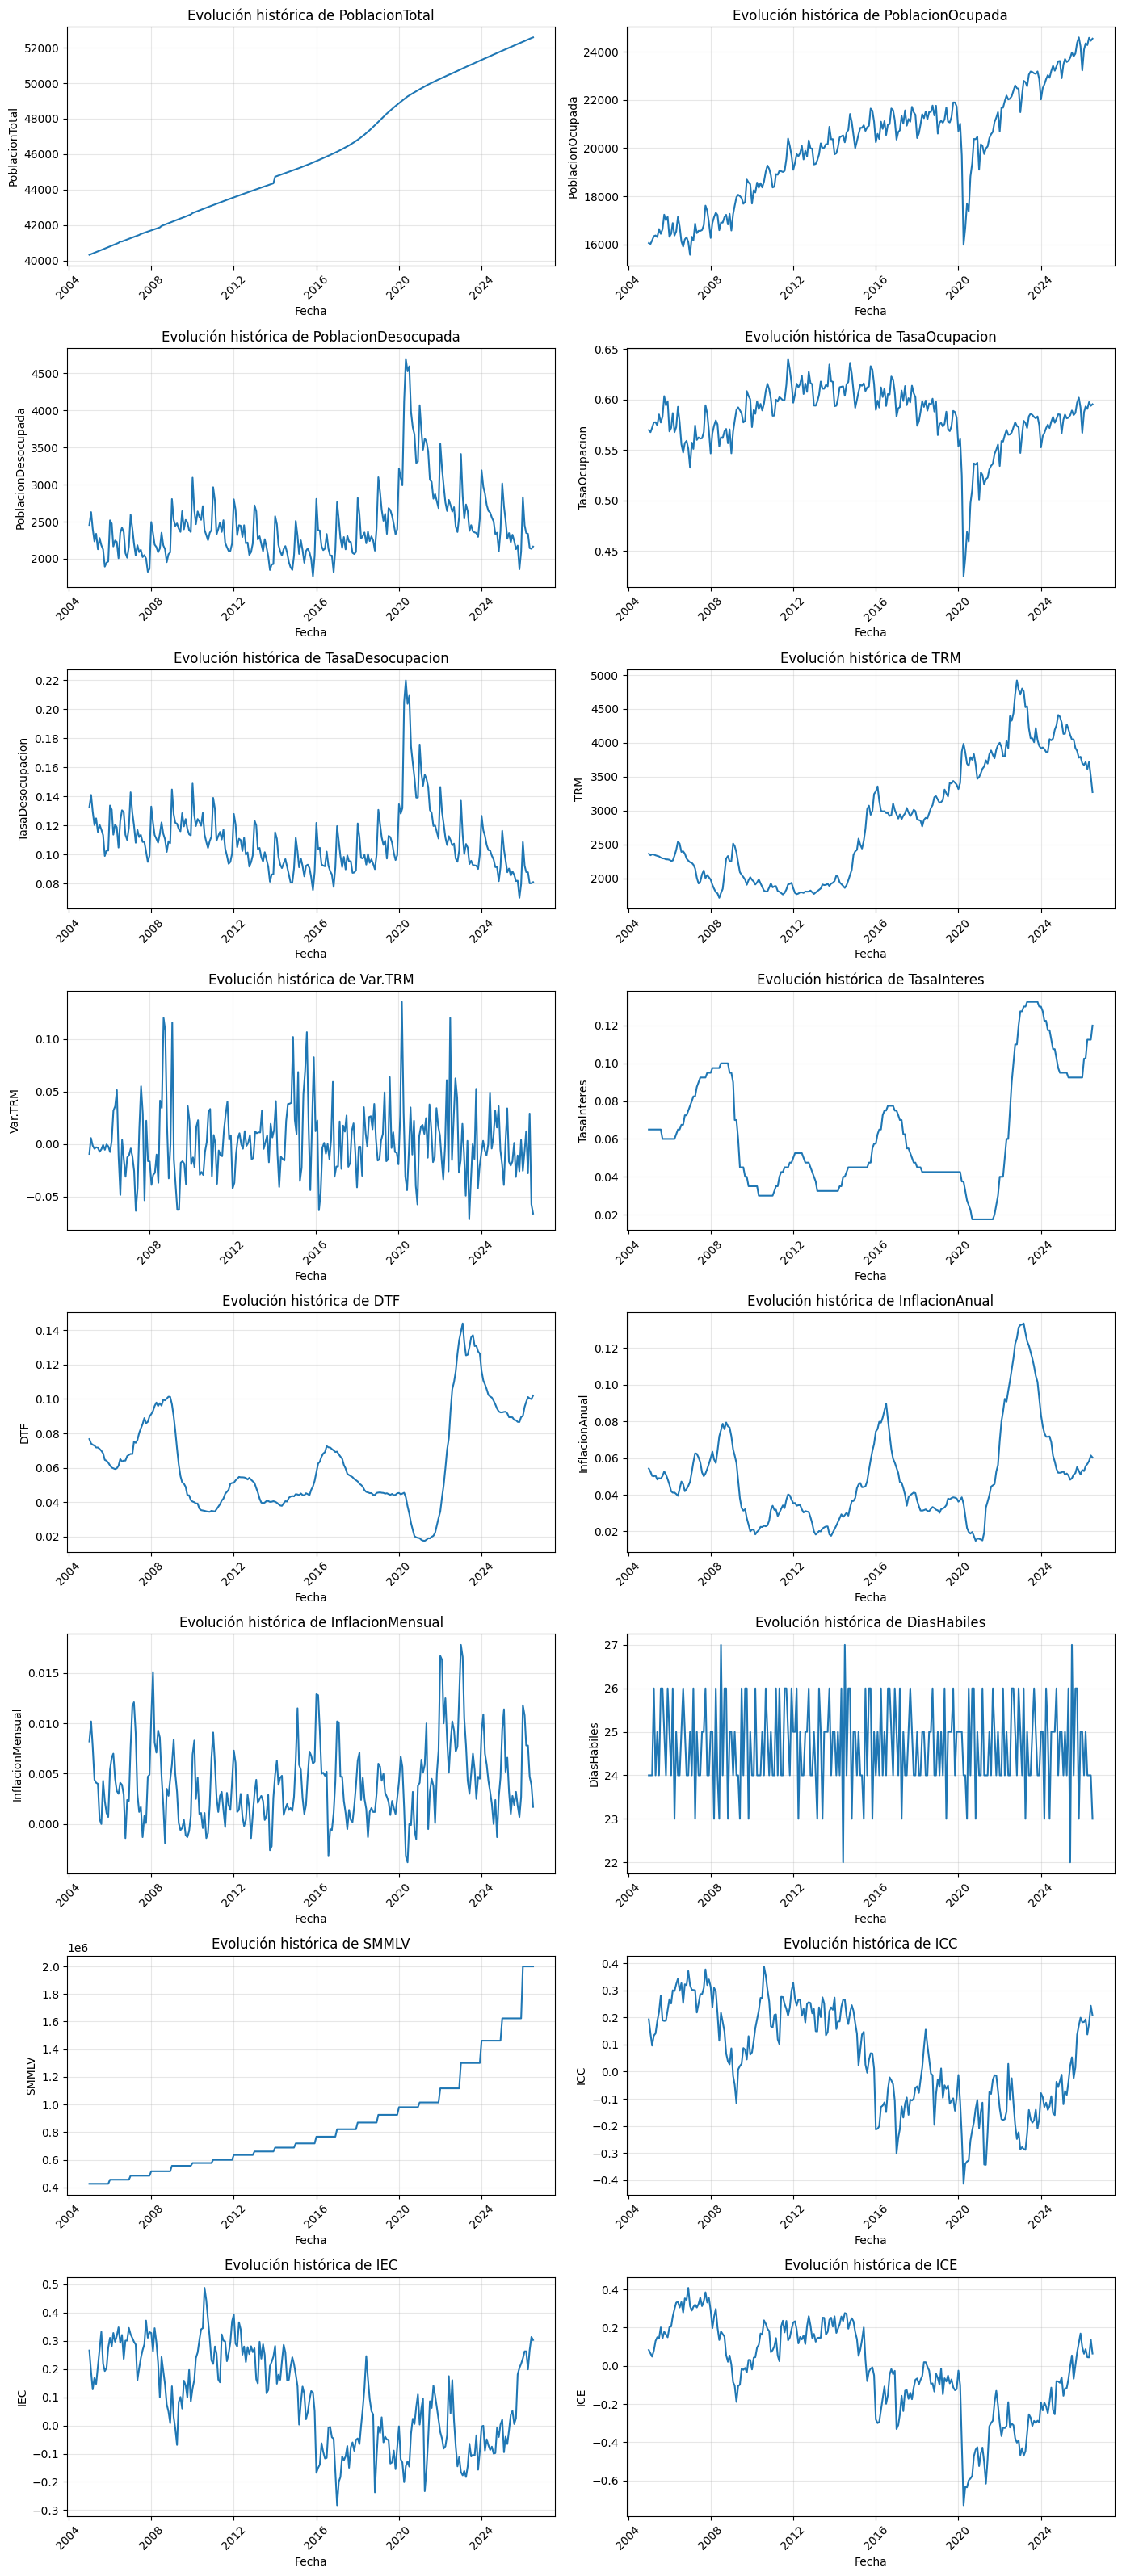

In [23]:
n_variables = len(variables_predictoras)

ncols = 2
nrows = math.ceil(n_variables / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(14, 4 * nrows)
)

# Convertir los ejes en una lista, incluso si hay una sola fila
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i, col in enumerate(variables_predictoras):

    datos = (
        df_datamarket_men[["Fecha", col]]
        .dropna()
        .sort_values("Fecha")
    )

    ax = axes[i]

    if datos.empty:
        ax.set_visible(False)
        continue

    ax.plot(datos["Fecha"], datos[col], linewidth=1.5)

    ax.set_title(f"Evolución histórica de {col}")
    ax.set_xlabel("Fecha")
    ax.set_ylabel(col)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, alpha=0.3)

# Ocultar espacios sobrantes en la cuadrícula
for j in range(n_variables, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

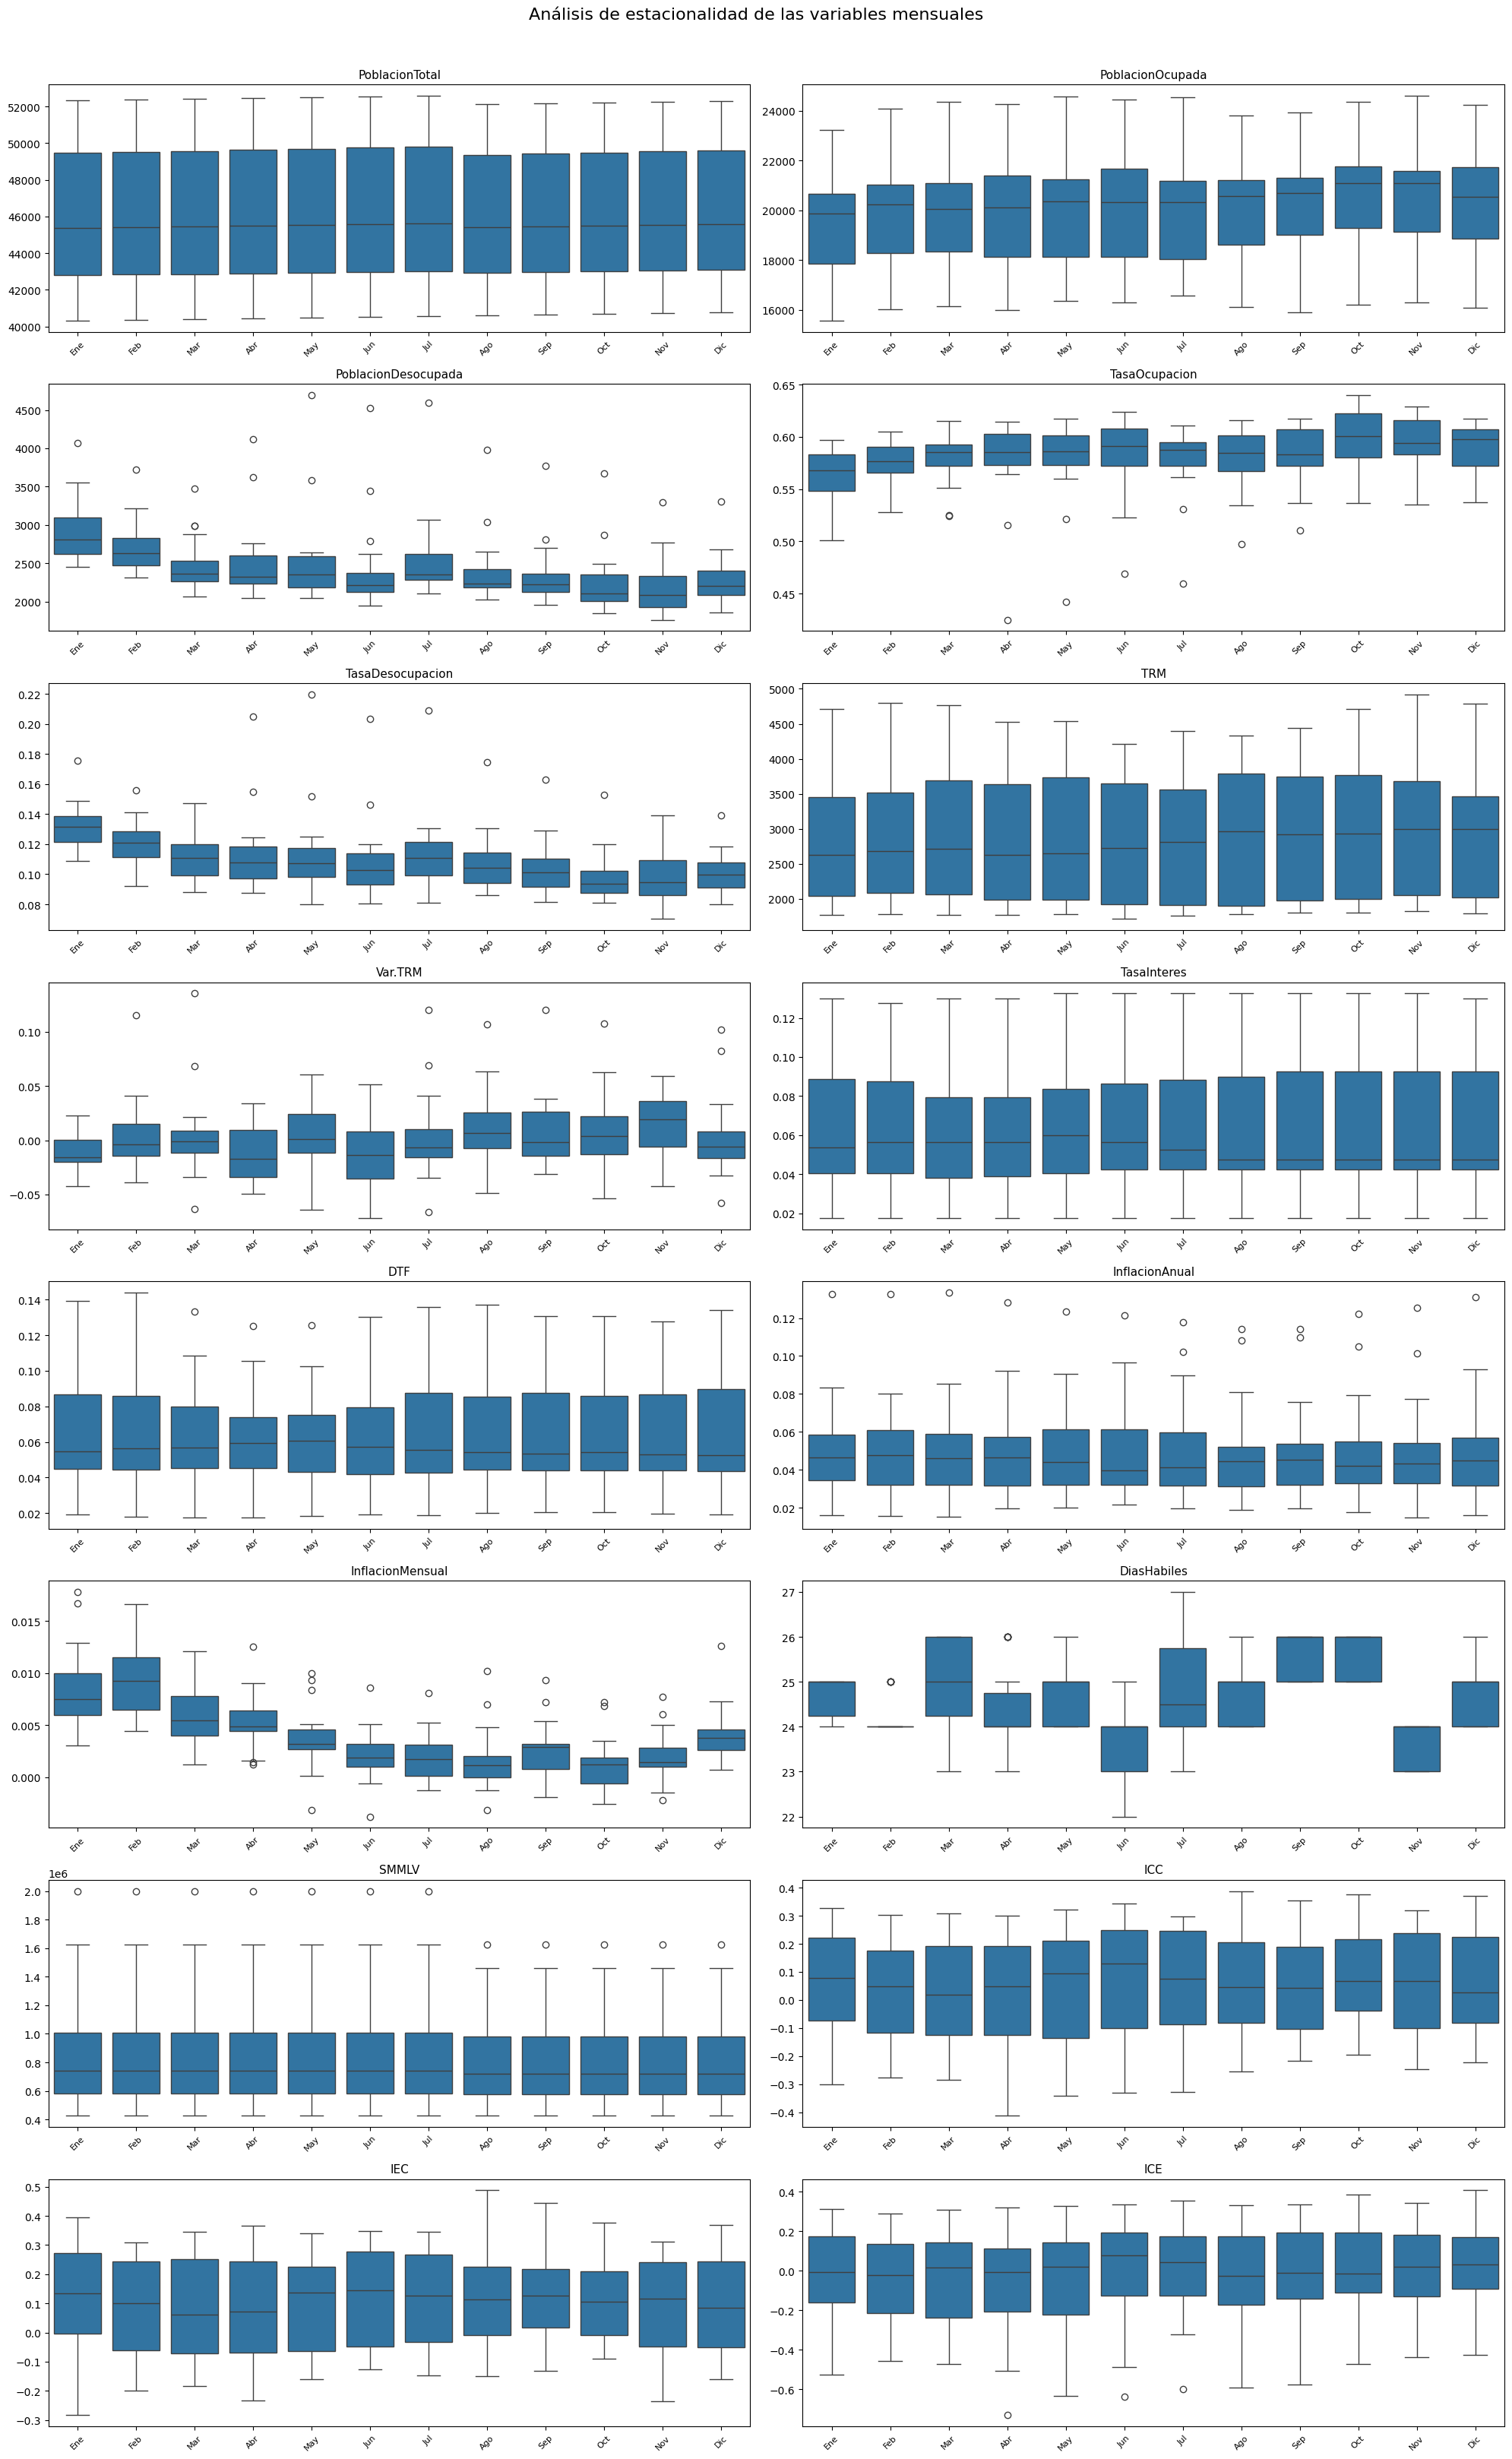

In [24]:
nombres_meses = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
]

variables_mensuales = [
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "TasaDesocupacion",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "DTF",
    "InflacionAnual",
    "InflacionMensual",
    "DiasHabiles",
    "SMMLV",
    "ICC",
    "IEC",
    "ICE"
]

# Filtrar variables disponibles
variables_disponibles = [
    col for col in variables_mensuales
    if col in df_datamarket_men.columns
]

# Definir cuadrícula
ncols = 2
nrows = math.ceil(len(variables_disponibles) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(20, 4 * nrows)
)

axes = axes.flatten()

for i, col in enumerate(variables_disponibles):

    temporal = df_datamarket_men[
        ["Fecha", col]
    ].dropna().copy()

    temporal["Mes"] = temporal["Fecha"].dt.month

    sns.boxplot(
        data=temporal,
        x="Mes",
        y=col,
        ax=axes[i]
    )

    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")
    axes[i].set_xticks(range(12))
    axes[i].set_xticklabels(nombres_meses, rotation=45, fontsize=8)

# Eliminar ejes vacíos
for j in range(len(variables_disponibles), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Análisis de estacionalidad de las variables mensuales",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

#####Variables: Periodicidad Trimestral

In [25]:
variables_predictoras = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas",
    "PIB_PC"
]

# Conservar únicamente las columnas que existan en la base
variables_predictoras = [
    col for col in variables_predictoras
    if col in df_datamarket_trim.columns
]

predictores = df_datamarket_trim[variables_predictoras].copy()

for col in variables_predictoras:
    predictores[col] = pd.to_numeric(
        predictores[col], errors="coerce"
    )

inventario = pd.DataFrame({
    "No_nulos": predictores.notna().sum(),
    "Faltantes": predictores.isna().sum(),
    "Porcentaje_faltantes": predictores.isna().mean() * 100,
    "Valores_unicos": predictores.nunique()
})

display(inventario.round(2))

,No_nulos,Faltantes,Porcentaje_faltantes,Valores_unicos
PIB,86,0,0.00,86
Var.PIB,85,1,1.16,85
Exportaciones,86,0,0.00,86
Importaciones,86,0,0.00,86
Remesas,86,0,0.00,86
PIB_PC,86,0,0.00,86


In [26]:
display(predictores.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
PIB,86.0,195860.250,38848.961,126088.657,159262.015,200982.445,221924.416,262061.542
Var.PIB,85.0,0.009,0.025,-0.162,0.004,0.008,0.015,0.099
Exportaciones,86.0,29760.482,4022.718,21334.353,25944.901,30801.073,32907.607,36079.445
Importaciones,86.0,42705.260,13024.832,18667.178,30688.300,44290.312,50785.145,67264.113
Remesas,86.0,1596.102,746.823,731.130,1012.065,1280.355,1941.225,3354.000
PIB_PC,86.0,421.482,52.396,312.434,371.379,437.484,456.383,499.110


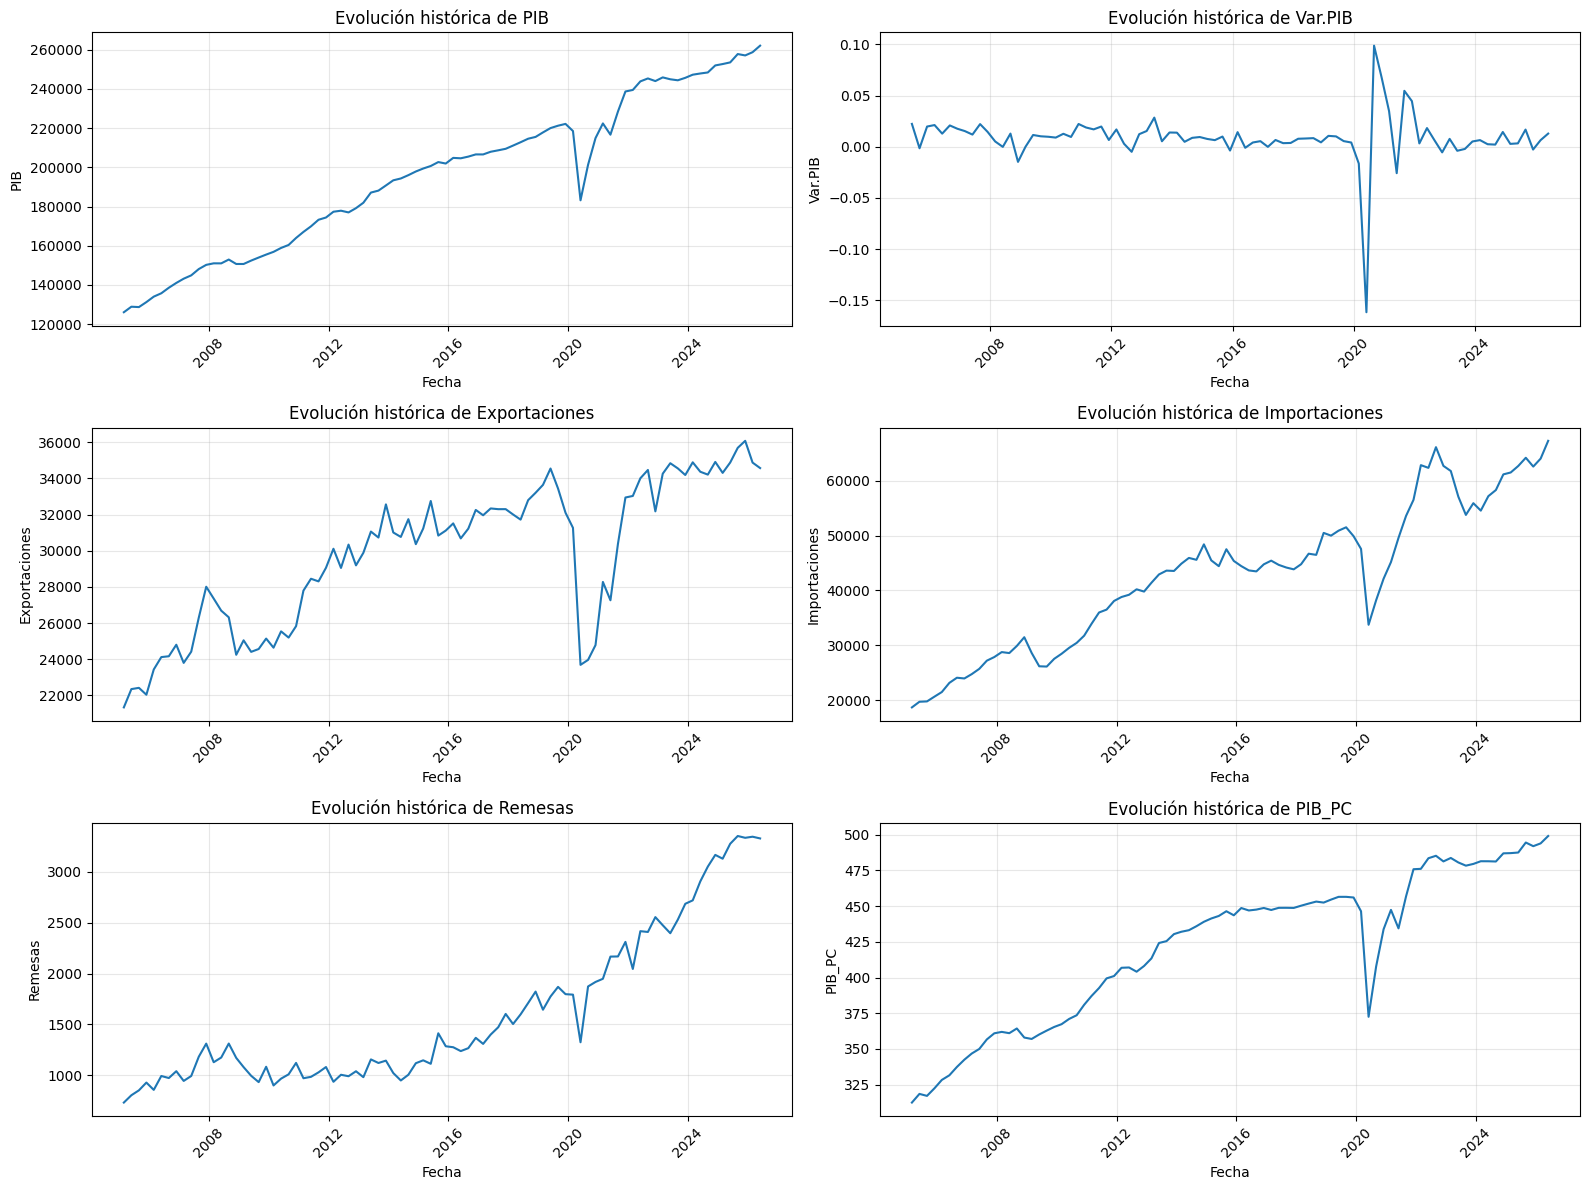

In [27]:
import matplotlib.pyplot as plt
import math

n_variables = len(variables_predictoras)

ncols = 2
nrows = math.ceil(n_variables / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(16, 4 * nrows)
)

# Convertir los ejes en una lista, incluso si hay una sola fila
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i, col in enumerate(variables_predictoras):

    datos = (
        df_datamarket_trim[["FechaFin", col]]
        .dropna()
        .sort_values("FechaFin")
    )

    ax = axes[i]

    if datos.empty:
        ax.set_visible(False)
        continue

    ax.plot(datos["FechaFin"], datos[col], linewidth=1.5)

    ax.set_title(f"Evolución histórica de {col}")
    ax.set_xlabel("Fecha")
    ax.set_ylabel(col)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, alpha=0.3)

# Ocultar espacios sobrantes en la cuadrícula
for j in range(n_variables, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

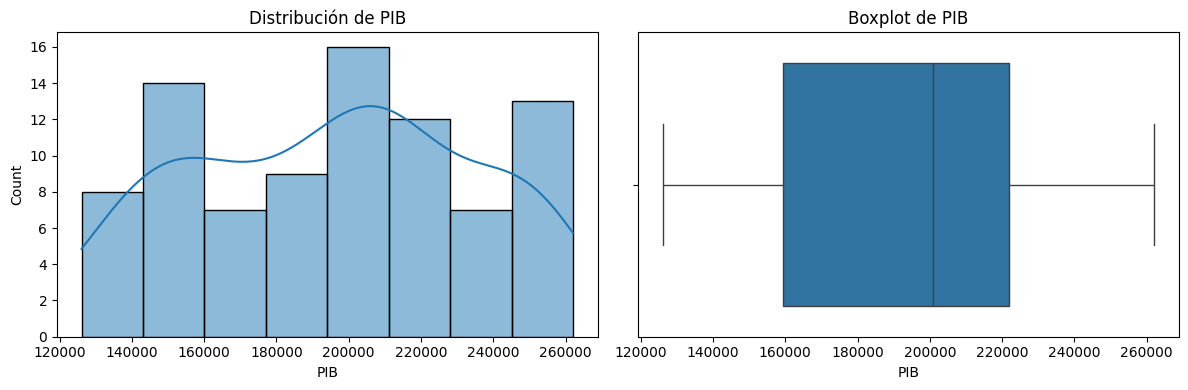

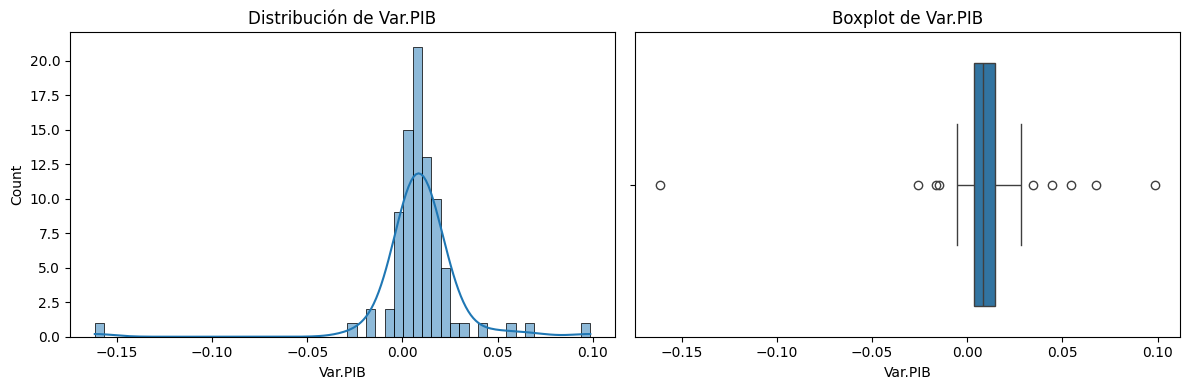

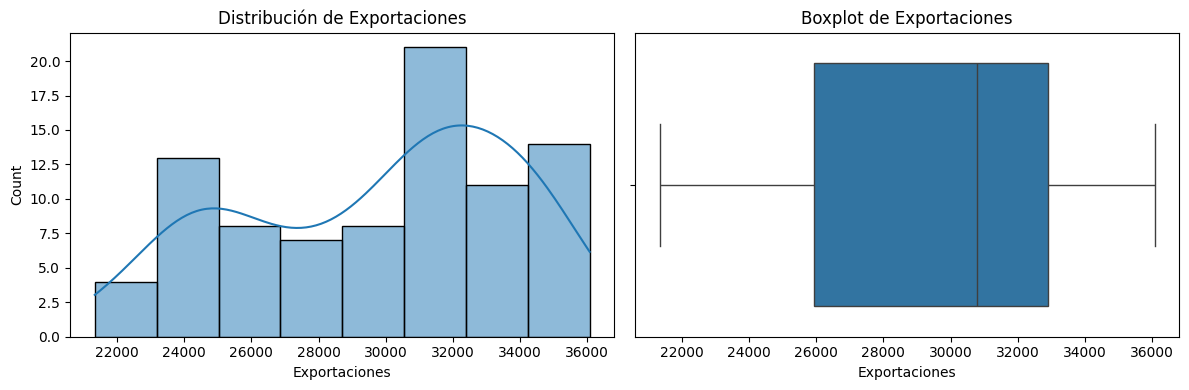

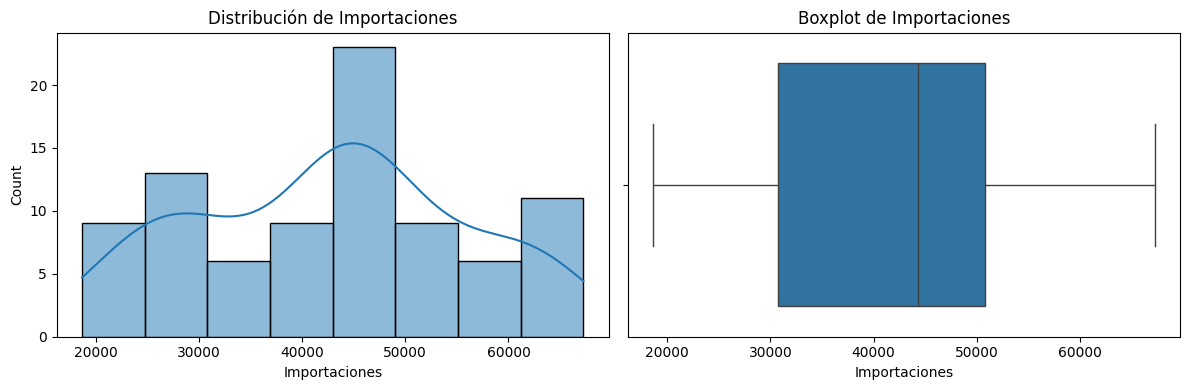

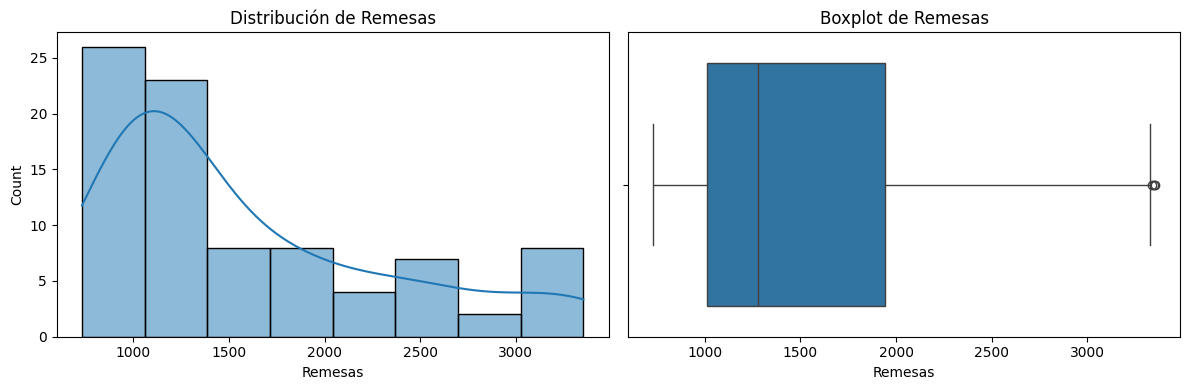

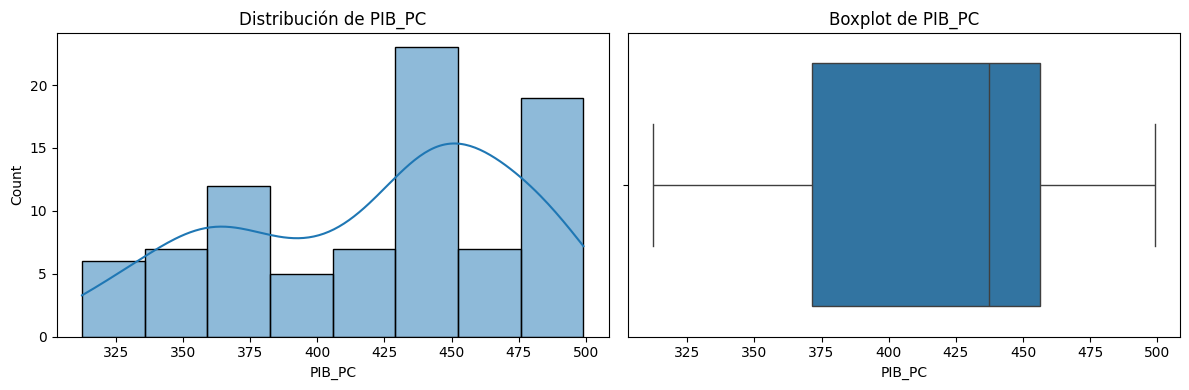

In [28]:
for col in variables_predictoras:

    datos = predictores[col].dropna()

    if datos.empty:
        continue

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(datos, kde=True, ax=axes[0])
    axes[0].set_title(f"Distribución de {col}")

    sns.boxplot(x=datos, ax=axes[1])
    axes[1].set_title(f"Boxplot de {col}")

    plt.tight_layout()
    plt.show()

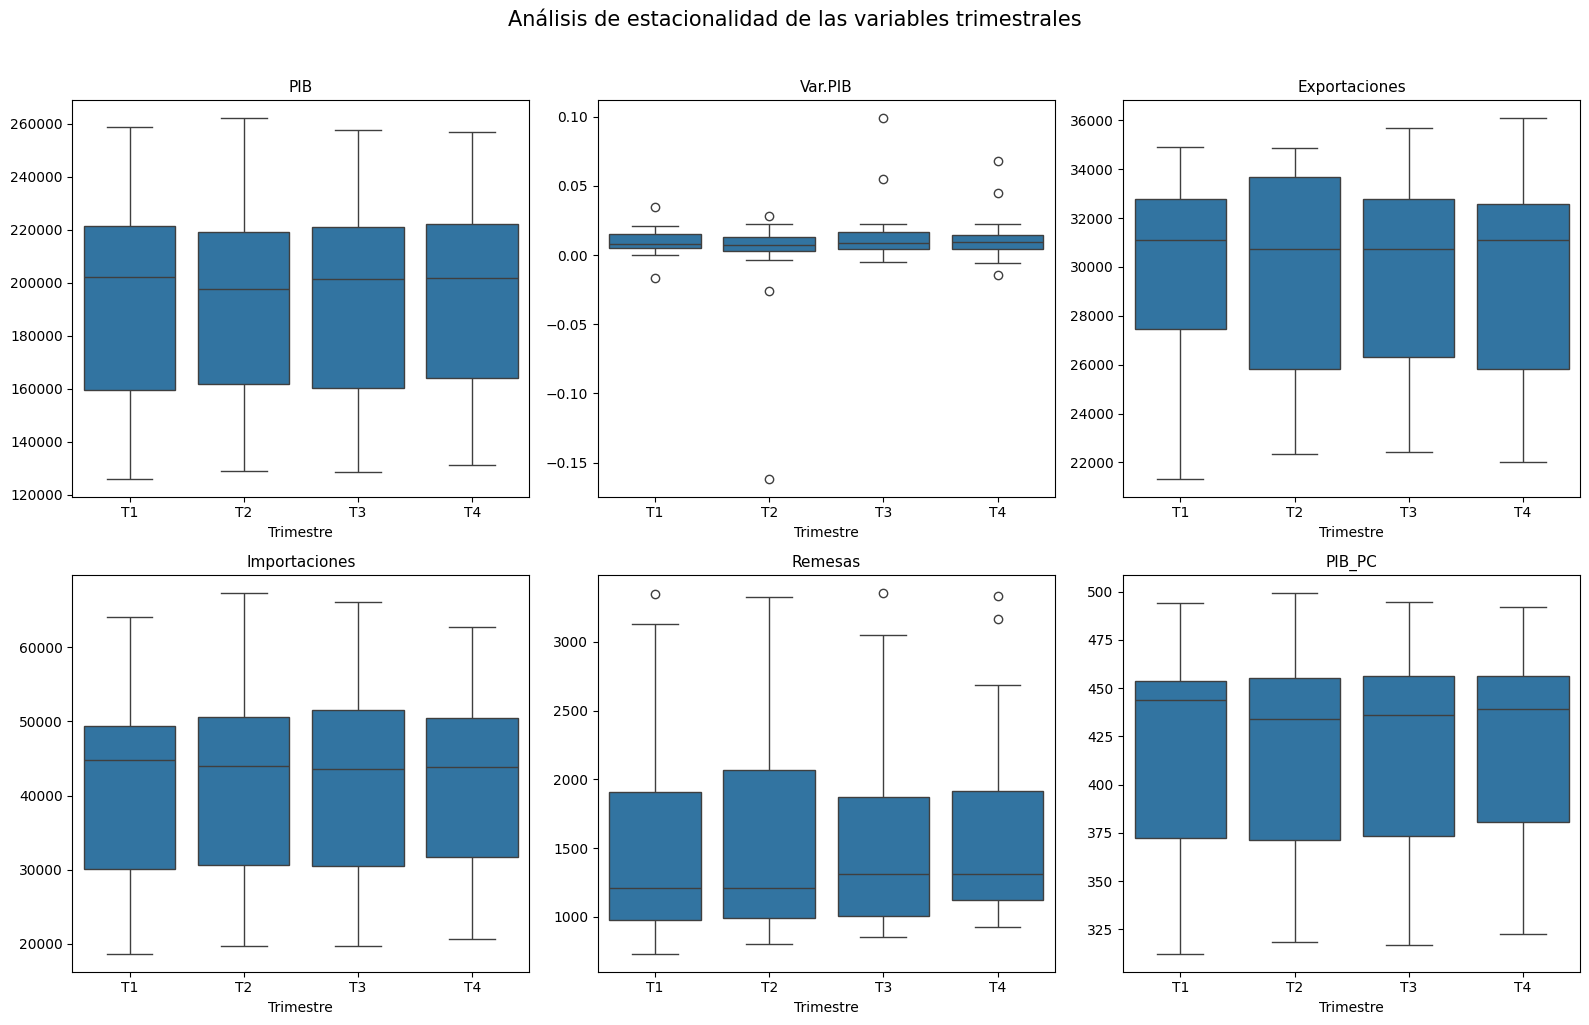

In [29]:
nombres_trimestres = ["T1", "T2", "T3", "T4"]

variables_trimestrales = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas",
    "PIB_PC"
]

# Conservar únicamente las variables que existen en el DataFrame
variables_disponibles = [
    col for col in variables_trimestrales
    if col in df_datamarket_trim.columns
]

ncols = 3
nrows = math.ceil(len(variables_disponibles) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(16, 5 * nrows)
)

axes = axes.flatten()

for i, col in enumerate(variables_disponibles):

    temporal = df_datamarket_trim[["FechaFin", col]].dropna().copy()

    temporal["Trimestre"] = temporal["FechaFin"].dt.quarter

    sns.boxplot(
        data=temporal,
        x="Trimestre",
        y=col,
        ax=axes[i]
    )

    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel("Trimestre")
    axes[i].set_ylabel("")
    axes[i].set_xticks(range(4))
    axes[i].set_xticklabels(nombres_trimestres)

# Eliminar espacios de gráficos que no se utilicen
for j in range(len(variables_disponibles), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Análisis de estacionalidad de las variables trimestrales",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()

####Relación entre las Variables

In [30]:
# Lista de predictores mensuales
variables_mensuales = [
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "TasaDesocupacion",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "DTF",
    "InflacionAnual",
    "InflacionMensual",
    "DiasHabiles",
    "SMMLV",
    "ICC",
    "IEC",
    "ICE"
]

# Conservar las variables disponibles
predictores_mensuales = [
    col for col in variables_mensuales
    if col in df_datamarket_men.columns
]


# Preparar las fechas sin modificar las bases originales
datos_objetivo = objetivo[["Fecha", "Registros"]].copy()
datos_predictores = df_datamarket_men[
    ["Fecha"] + predictores_mensuales
].copy()

datos_objetivo["Fecha"] = pd.to_datetime(datos_objetivo["Fecha"])
datos_predictores["Fecha"] = pd.to_datetime(datos_predictores["Fecha"])


# Integrar ambas bases
base_analisis = datos_objetivo.merge(
    datos_predictores,
    on="Fecha",
    how="inner",
    validate="one_to_one"
)

base_analisis = base_analisis.sort_values("Fecha").reset_index(drop=True)


columnas_correlacion = ["Registros"] + predictores_mensuales

corr_pearson = base_analisis[
    columnas_correlacion
].corr(method="pearson", numeric_only=True)

corr_spearman = base_analisis[
    columnas_correlacion
].corr(method="spearman", numeric_only=True)


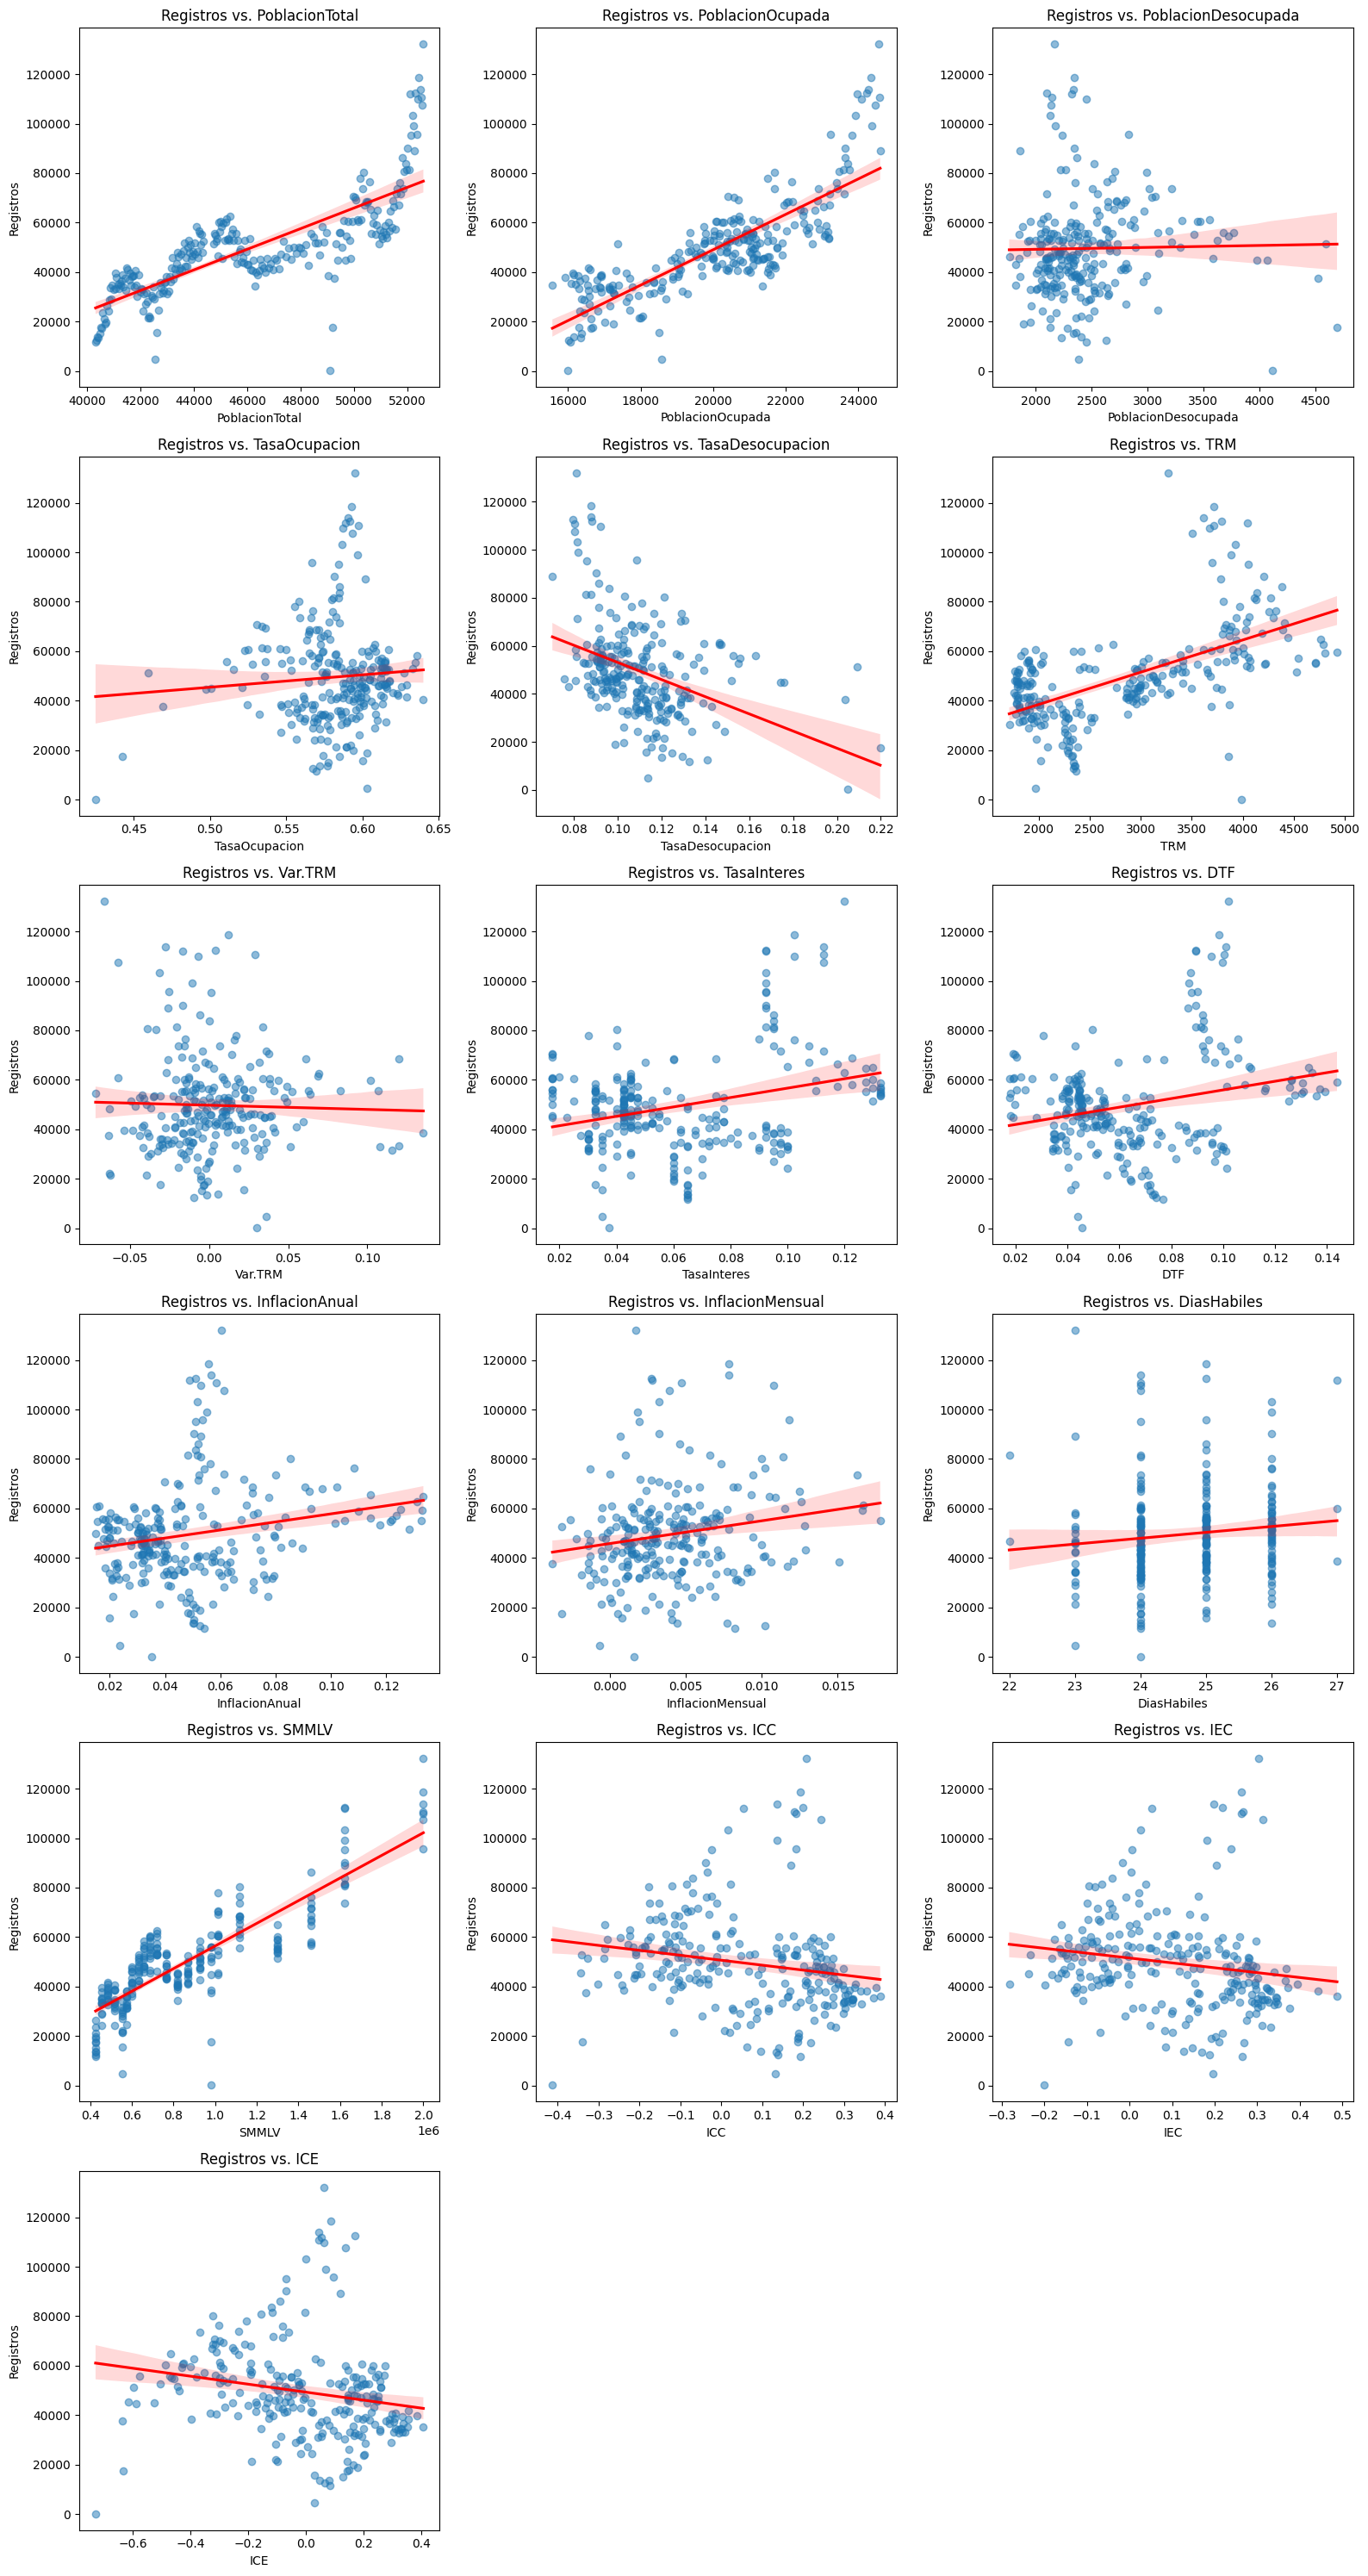

In [31]:
variables_graficos = [
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "TasaDesocupacion",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "DTF",
    "InflacionAnual",
    "InflacionMensual",
    "DiasHabiles",
    "SMMLV",
    "ICC",
    "IEC",
    "ICE"
]

variables_graficos = [
    col for col in variables_graficos
    if col in base_analisis.columns
]

ncols = 3
nrows = math.ceil(len(variables_graficos) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(16, 5 * nrows)
)

axes = np.array(axes).flatten()

for i, col in enumerate(variables_graficos):

    temporal = base_analisis[
        ["Registros", col]
    ].dropna()

    sns.regplot(
        data=temporal,
        x=col,
        y="Registros",
        scatter_kws={"alpha": 0.5},
        line_kws={"color": "red"},
        ax=axes[i]
    )

    axes[i].set_title(f"Registros vs. {col}")

for j in range(len(variables_graficos), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

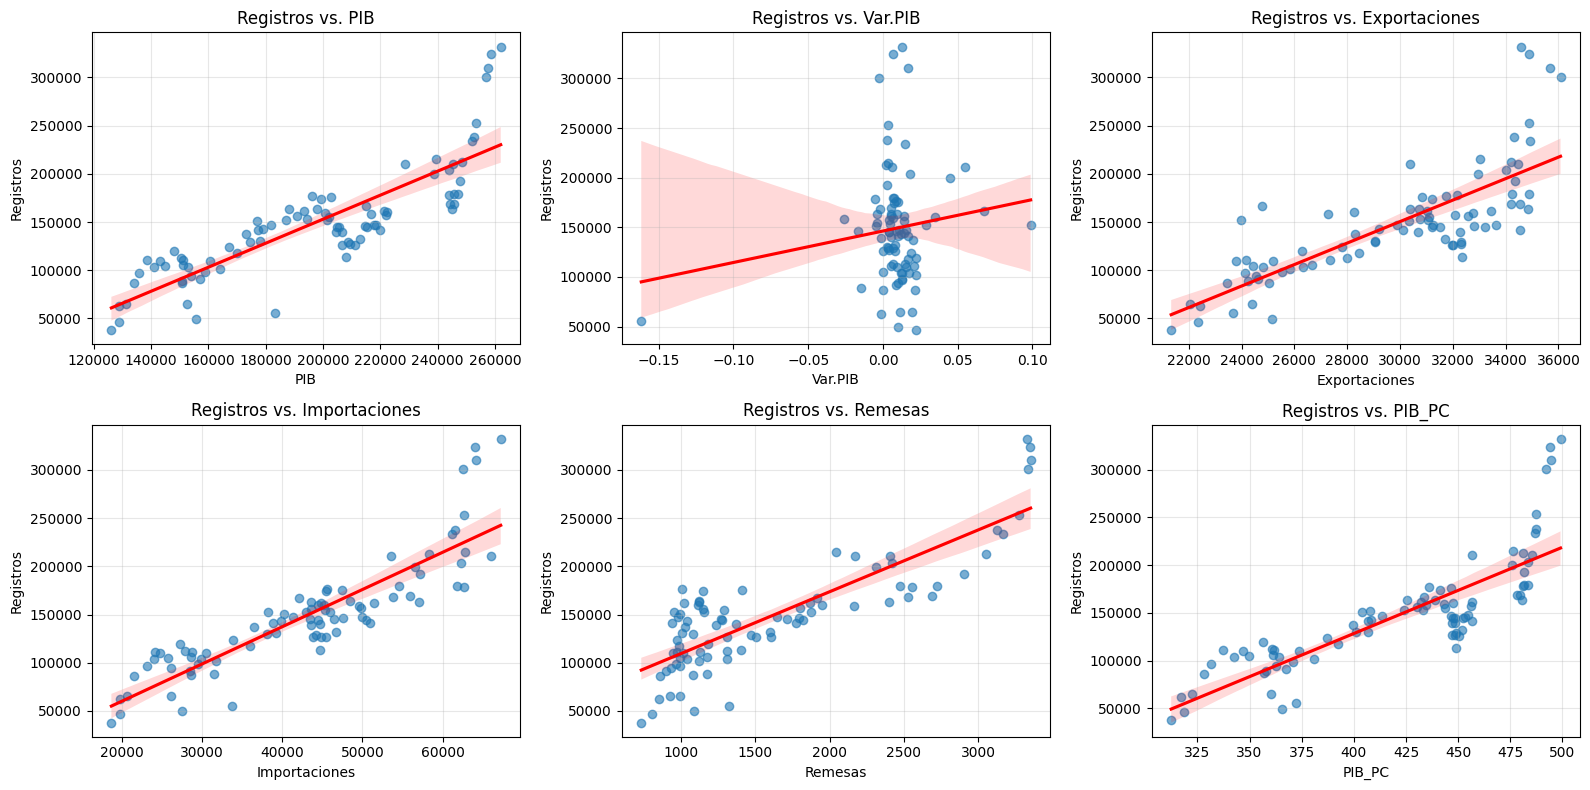

In [32]:
df = df_datamarket_trim.copy()

variables_trimestrales = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas",
    "PIB_PC"
]

ncols = 3
nrows = math.ceil(len(variables_trimestrales) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, 4 * nrows)
)

axes = axes.flatten()

for i, variable in enumerate(variables_trimestrales):
    sns.regplot(
        data=df,
        x=variable,
        y="Registros",
        ax=axes[i],
        scatter_kws={"alpha": 0.6},
        line_kws={"color": "red"}
    )

    axes[i].set_title(f"Registros vs. {variable}")
    axes[i].grid(True, alpha=0.3)

for j in range(len(variables_trimestrales), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

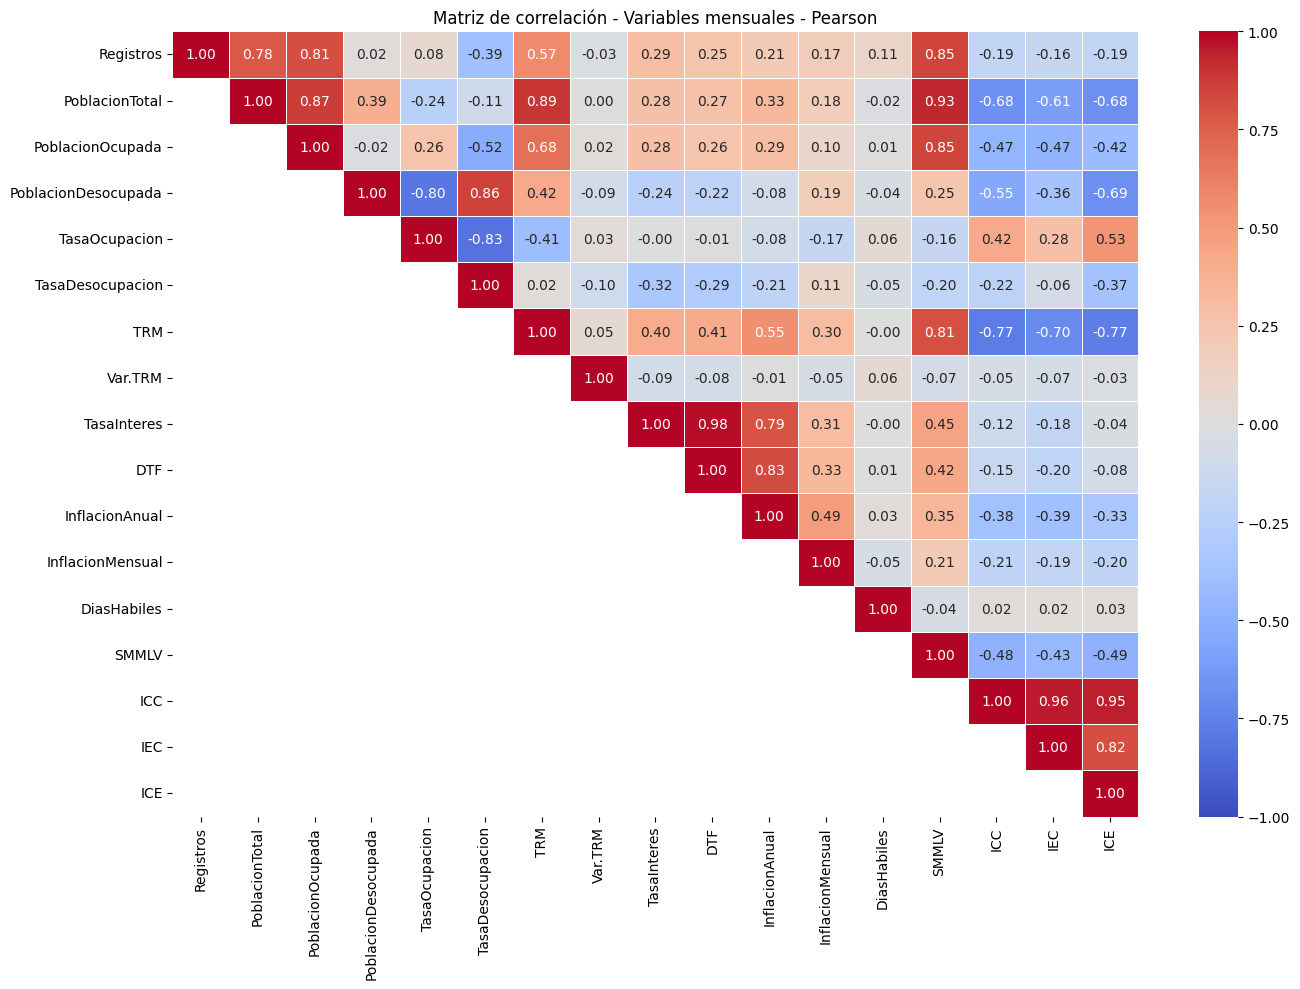

In [40]:
# Seleccionar variables numéricas
variables = df_datamarket_men.select_dtypes(include="number")

# Calcular la matriz de correlación de Pearson
matriz_corr = variables.corr(method="pearson")

# Crear máscara para ocultar el triángulo inferior
mascara = np.tril(np.ones_like(matriz_corr, dtype=bool), k=-1)

# Visualizar la matriz
plt.figure(figsize=(14, 10))

sns.heatmap(
    matriz_corr,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Matriz de correlación - Variables mensuales - Pearson")
plt.tight_layout()
plt.show()

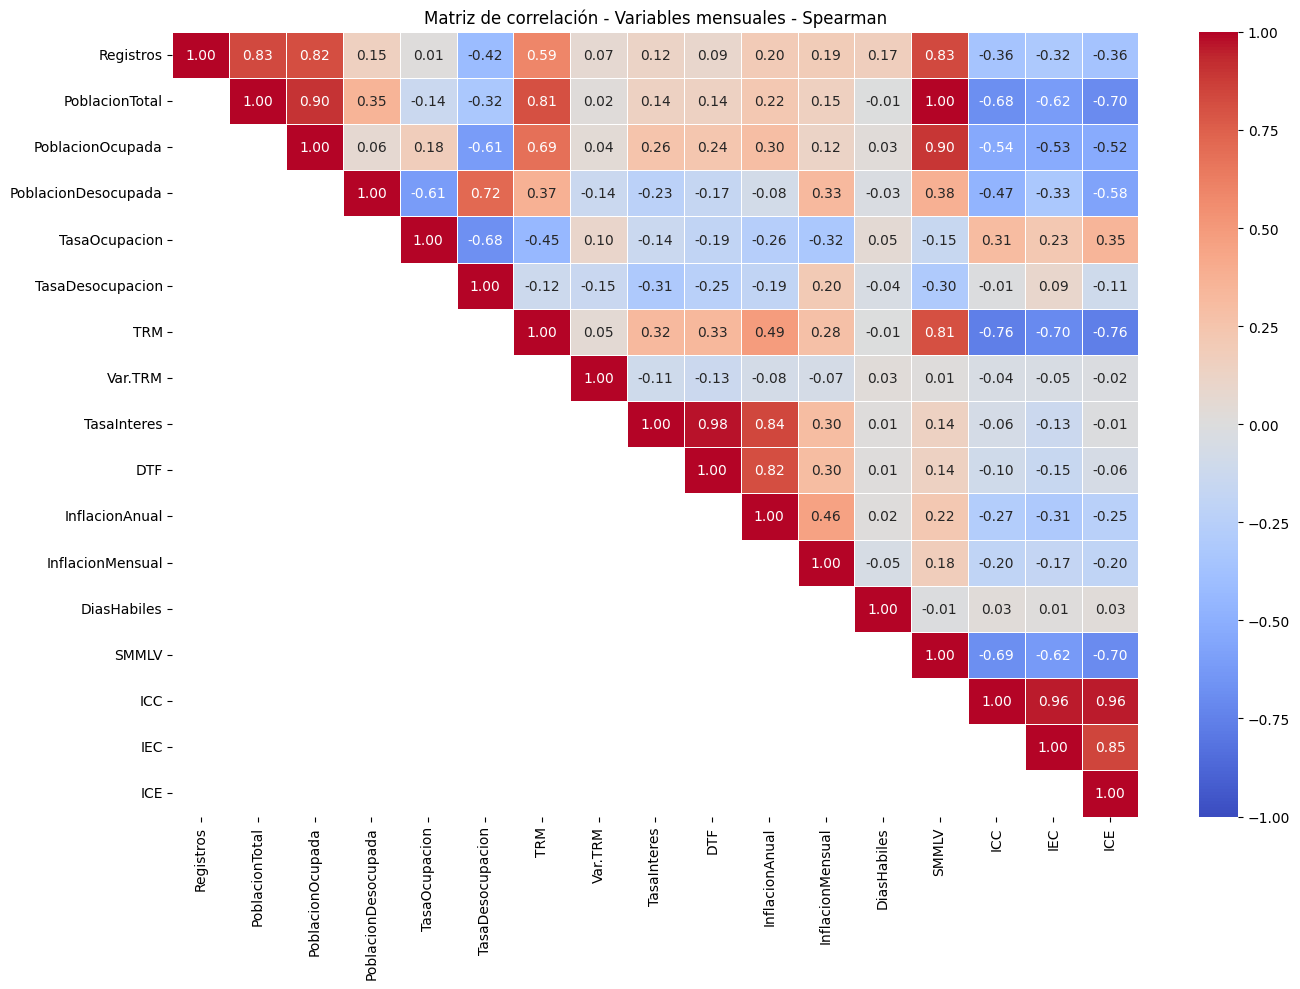

In [41]:
# Seleccionar variables numéricas
variables = df_datamarket_men.select_dtypes(include="number")

# Calcular la matriz de correlación de Spearman
matriz_corr = variables.corr(method="spearman")

# Crear máscara para ocultar el triángulo inferior
mascara = np.tril(np.ones_like(matriz_corr, dtype=bool), k=-1)

# Visualizar la matriz
plt.figure(figsize=(14, 10))

sns.heatmap(
    matriz_corr,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Matriz de correlación - Variables mensuales - Spearman")
plt.tight_layout()
plt.show()

In [33]:
resultados_rezagos = []

for col in predictores_mensuales:

    for lag in range(0, 13):

        temporal = base_analisis[
            ["Fecha", "Registros", col]
        ].copy()

        # Predictor observado lag meses antes
        temporal["Predictor_rezagado"] = temporal[col].shift(lag)

        temporal = temporal[
            ["Registros", "Predictor_rezagado"]
        ].dropna()

        if len(temporal) < 12:
            continue

        correlacion = temporal["Registros"].corr(
            temporal["Predictor_rezagado"],
            method="spearman"
        )

        resultados_rezagos.append({
            "Variable": col,
            "Rezago_meses": lag,
            "Correlacion_Spearman": correlacion,
            "Observaciones": len(temporal)
        })

tabla_rezagos = pd.DataFrame(resultados_rezagos)
display(tabla_rezagos)

,Variable,Rezago_meses,Correlacion_Spearman,Observaciones
0,PoblacionTotal,0,0.832766,259
1,PoblacionTotal,1,0.831013,258
2,PoblacionTotal,2,0.829202,257
3,PoblacionTotal,3,0.827363,256
4,PoblacionTotal,4,0.825476,255
...,...,...,...,...
203,ICE,8,-0.440433,251
204,ICE,9,-0.445332,250
205,ICE,10,-0.474486,249
206,ICE,11,-0.486811,248


In [34]:
mejores_rezagos = (
    tabla_rezagos
    .assign(
        Abs_Correlacion=lambda df:
            df["Correlacion_Spearman"].abs()
    )
    .sort_values(
        ["Variable", "Abs_Correlacion"],
        ascending=[True, False]
    )
    .groupby("Variable")
    .head(3)
    .sort_values("Variable")
)

display(mejores_rezagos)

,Variable,Rezago_meses,Correlacion_Spearman,Observaciones,Abs_Correlacion
116,DTF,12,-0.135083,247,0.135083
115,DTF,11,-0.124611,248,0.124611
114,DTF,10,-0.113592,249,0.113592
143,DiasHabiles,0,0.167785,259,0.167785
144,DiasHabiles,1,-0.101707,258,0.101707
154,DiasHabiles,11,0.078573,248,0.078573
181,ICC,12,-0.472618,247,0.472618
180,ICC,11,-0.470460,248,0.470460
179,ICC,10,-0.458942,249,0.458942
205,ICE,10,-0.474486,249,0.474486


In [35]:
variables_trimestrales = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas",
    "PIB_PC"
]

predictores_trim_disponibles = [
    col for col in variables_trimestrales
    if col in df_datamarket_trim.columns
]

# Registros mensuales agrupados por trimestre
datos_registros = objetivo[["Fecha", "Registros"]].copy()

datos_registros["Trimestre"] = (
    datos_registros["Fecha"].dt.to_period("Q")
)

registros_trim = (
    datos_registros
    .groupby("Trimestre", as_index=False)
    .agg(Registros=("Registros", "sum"))
)

# Preparar predictores trimestrales
datos_trim = df_datamarket_trim[
    ["FechaFin"] + predictores_trim_disponibles
].copy()

datos_trim["Trimestre"] = (
    datos_trim["FechaFin"].dt.to_period("Q")
)

# Verificar que exista un único registro por trimestre
print(
    "Trimestres duplicados en predictores:",
    datos_trim["Trimestre"].duplicated().sum()
)

# Integrar ambas bases por trimestre
base_trimestral = registros_trim.merge(
    datos_trim[["Trimestre"] + predictores_trim_disponibles],
    on="Trimestre",
    how="inner",
    validate="one_to_one"
)

display(base_trimestral.head())

Trimestres duplicados en predictores: 0


,Trimestre,Registros,PIB,Var.PIB,Exportaciones,Importaciones,Remesas,PIB_PC
0,2005Q1,37999,126088.657004,NaN,21334.353184,18667.177575,731.13,312.433757
1,2005Q2,46544,128906.474678,0.022348,22346.501950,19696.555294,803.26,318.501879
2,2005Q3,62445,128717.054381,-0.001469,22416.208758,19760.125657,851.47,317.114632
3,2005Q4,65080,131260.139968,0.019757,22034.764695,20628.289335,927.86,322.419309
4,2006Q1,86446,134044.350100,0.021211,23431.599497,21467.411899,855.89,328.288713


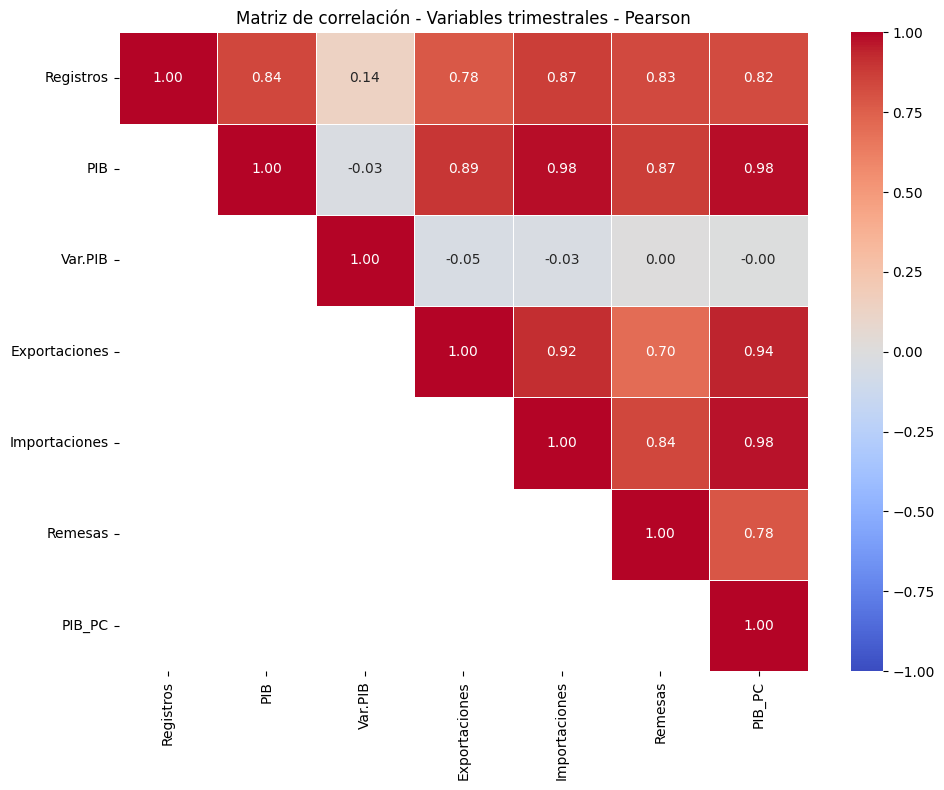

In [45]:
variables_trimestrales = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas",
    "PIB_PC"
]

# Seleccionar variables trimestrales + variable objetivo
variables_corr = ["Registros"] + variables_trimestrales

# Seleccionar únicamente las columnas de interés
datos_corr = df_datamarket_trim[variables_corr]

# Calcular la matriz de correlación de Pearson
matriz_corr = datos_corr.corr(method="pearson")

# Crear máscara para ocultar el triángulo inferior
mascara = np.tril(
    np.ones_like(matriz_corr, dtype=bool),
    k=-1
)

# Visualizar la matriz
plt.figure(figsize=(10, 8))

sns.heatmap(
    matriz_corr,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Matriz de correlación - Variables trimestrales - Pearson")
plt.tight_layout()
plt.show()

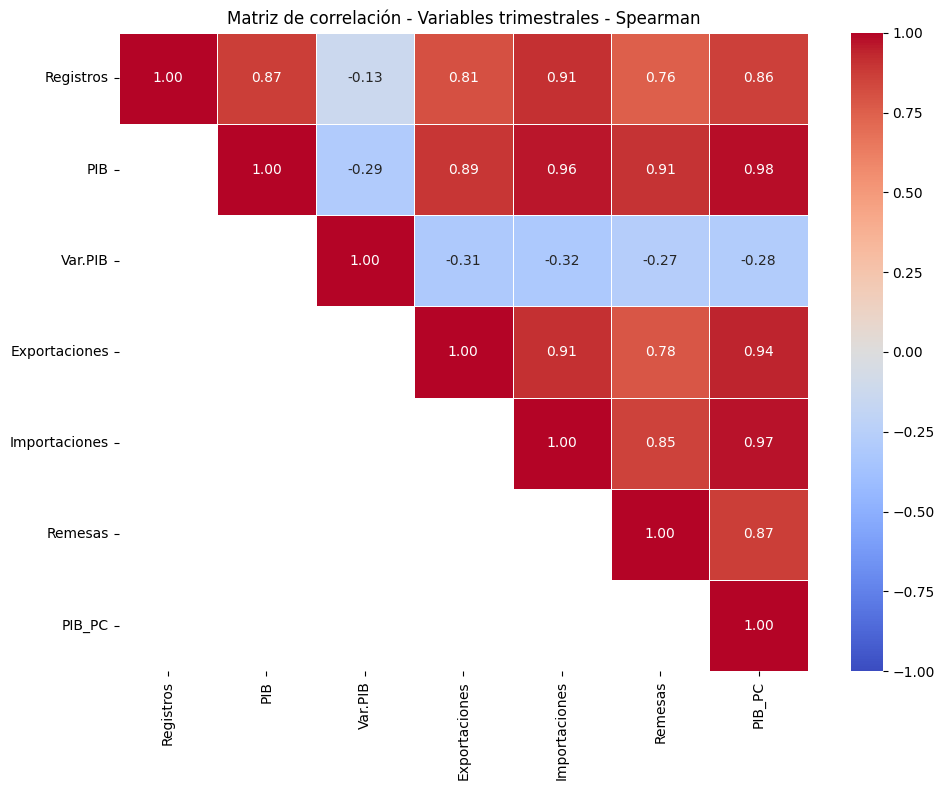

In [46]:
variables_trimestrales = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas",
    "PIB_PC"
]

# Seleccionar variables trimestrales + variable objetivo
variables_corr = ["Registros"] + variables_trimestrales

# Seleccionar únicamente las columnas de interés
datos_corr = df_datamarket_trim[variables_corr]

# Calcular la matriz de correlación de Pearson
matriz_corr = datos_corr.corr(method="spearman")

# Crear máscara para ocultar el triángulo inferior
mascara = np.tril(
    np.ones_like(matriz_corr, dtype=bool),
    k=-1
)

# Visualizar la matriz
plt.figure(figsize=(10, 8))

sns.heatmap(
    matriz_corr,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Matriz de correlación - Variables trimestrales - Spearman")
plt.tight_layout()
plt.show()

In [47]:
# Ordenar por fecha
df_datamercado = df_datamarket_men.sort_values("Fecha").copy()

# Identificar variables explicativas numéricas
variables_explicativas = [
    c for c in df_datamercado.select_dtypes(include="number").columns
    if c != "Registros"
]

# Evaluar rezagos trimestrales
rezagos = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

resultados = []

for variable in variables_explicativas:
    for rezago in rezagos:

        correlacion = df_datamercado["Registros"].corr(
            df_datamercado[variable].shift(rezago)
        )

        resultados.append({
            "Variable": variable,
            "Rezago_mensuales": rezago,
            "Correlacion": correlacion
        })

tabla_rezagos = pd.DataFrame(resultados)

print(
    tabla_rezagos.sort_values(
        "Correlacion",
        key=lambda x: x.abs(),
        ascending=False
    ).to_string(index=False)
)

           Variable  Rezago_mensuales  Correlacion
              SMMLV                 1     0.851407
              SMMLV                 2     0.848491
              SMMLV                 0     0.848283
              SMMLV                 6     0.845897
              SMMLV                 4     0.843916
              SMMLV                 3     0.843764
              SMMLV                 5     0.843362
              SMMLV                11     0.839600
              SMMLV                 7     0.836394
              SMMLV                12     0.836335
              SMMLV                 8     0.834937
              SMMLV                10     0.834908
              SMMLV                 9     0.834158
   PoblacionOcupada                 0     0.812779
   PoblacionOcupada                 1     0.784972
     PoblacionTotal                 0     0.777352
     PoblacionTotal                 1     0.776039
     PoblacionTotal                 2     0.774562
     PoblacionTotal            

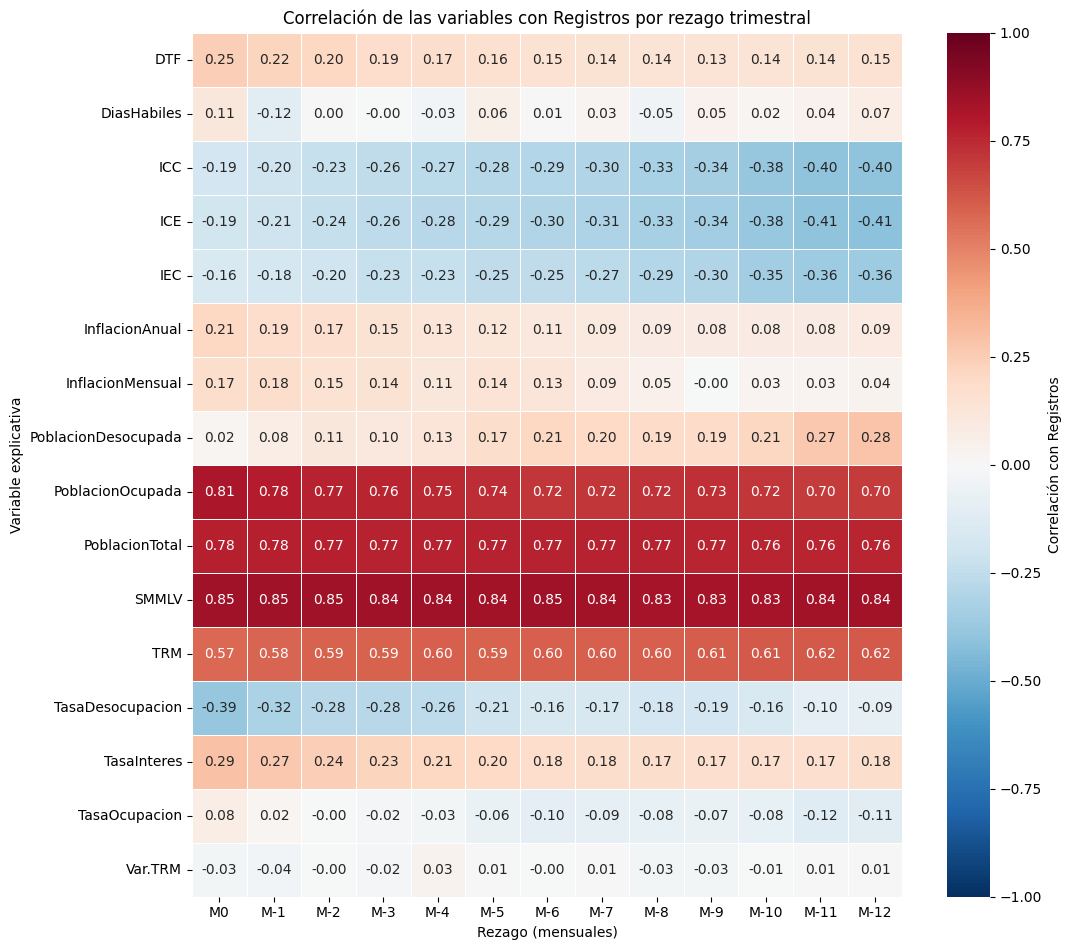

In [48]:
# Organizar los resultados en una matriz
mapa_rezagos = tabla_rezagos.pivot(
    index="Variable",
    columns="Rezago_mensuales",
    values="Correlacion"
)

# Ordenar columnas de 0 a 4 trimestres
mapa_rezagos = mapa_rezagos.reindex(
    columns=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
)

# Graficar
plt.figure(figsize=(11, max(5, len(mapa_rezagos) * 0.6)))

sns.heatmap(
    mapa_rezagos,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Correlación con Registros"}
)

plt.title("Correlación de las variables con Registros por rezago trimestral")
plt.xlabel("Rezago (mensuales)")
plt.ylabel("Variable explicativa")
plt.xticks(
    ticks=[i + 0.5 for i in range(13)],
    labels=["M0", "M-1", "M-2", "M-3", "M-4", "M-5", "M-6", "M-7", "M-8", "M-9", "M-10", "M-11", "M-12"],
    rotation=0
)

plt.tight_layout()
plt.show()

In [50]:
# Ordenar por fecha
df_datamercado = df_datamarket_trim.sort_values("FechaFin").copy()

# Identificar variables explicativas numéricas
variables_explicativas = [
    c for c in df_datamercado.select_dtypes(include="number").columns
    if c != "Registros"
]

# Evaluar rezagos trimestrales
rezagos = [0, 1, 2, 3, 4]

resultados = []

for variable in variables_explicativas:
    for rezago in rezagos:

        correlacion = df_datamercado["Registros"].corr(
            df_datamercado[variable].shift(rezago)
        )

        resultados.append({
            "Variable": variable,
            "Rezago_trimestrales": rezago,
            "Correlacion": correlacion
        })

tabla_rezagos = pd.DataFrame(resultados)

print(
    tabla_rezagos.sort_values(
        "Correlacion",
        key=lambda x: x.abs(),
        ascending=False
    ).to_string(index=False)
)

           Variable  Rezago_trimestrales  Correlacion
      Importaciones                    0     0.874650
              SMMLV                    0     0.862802
              SMMLV                    2     0.859101
              SMMLV                    1     0.857495
              SMMLV                    4     0.855872
              SMMLV                    3     0.854075
                PIB                    0     0.841536
            Remesas                    0     0.832503
   PoblacionOcupada                    0     0.830264
            Remesas                    1     0.824898
             PIB_PC                    0     0.823751
      Importaciones                    1     0.823356
            Remesas                    3     0.813263
            Remesas                    2     0.812139
                PIB                    1     0.805513
            Remesas                    4     0.803619
     PoblacionTotal                    0     0.798461
     PoblacionTotal         

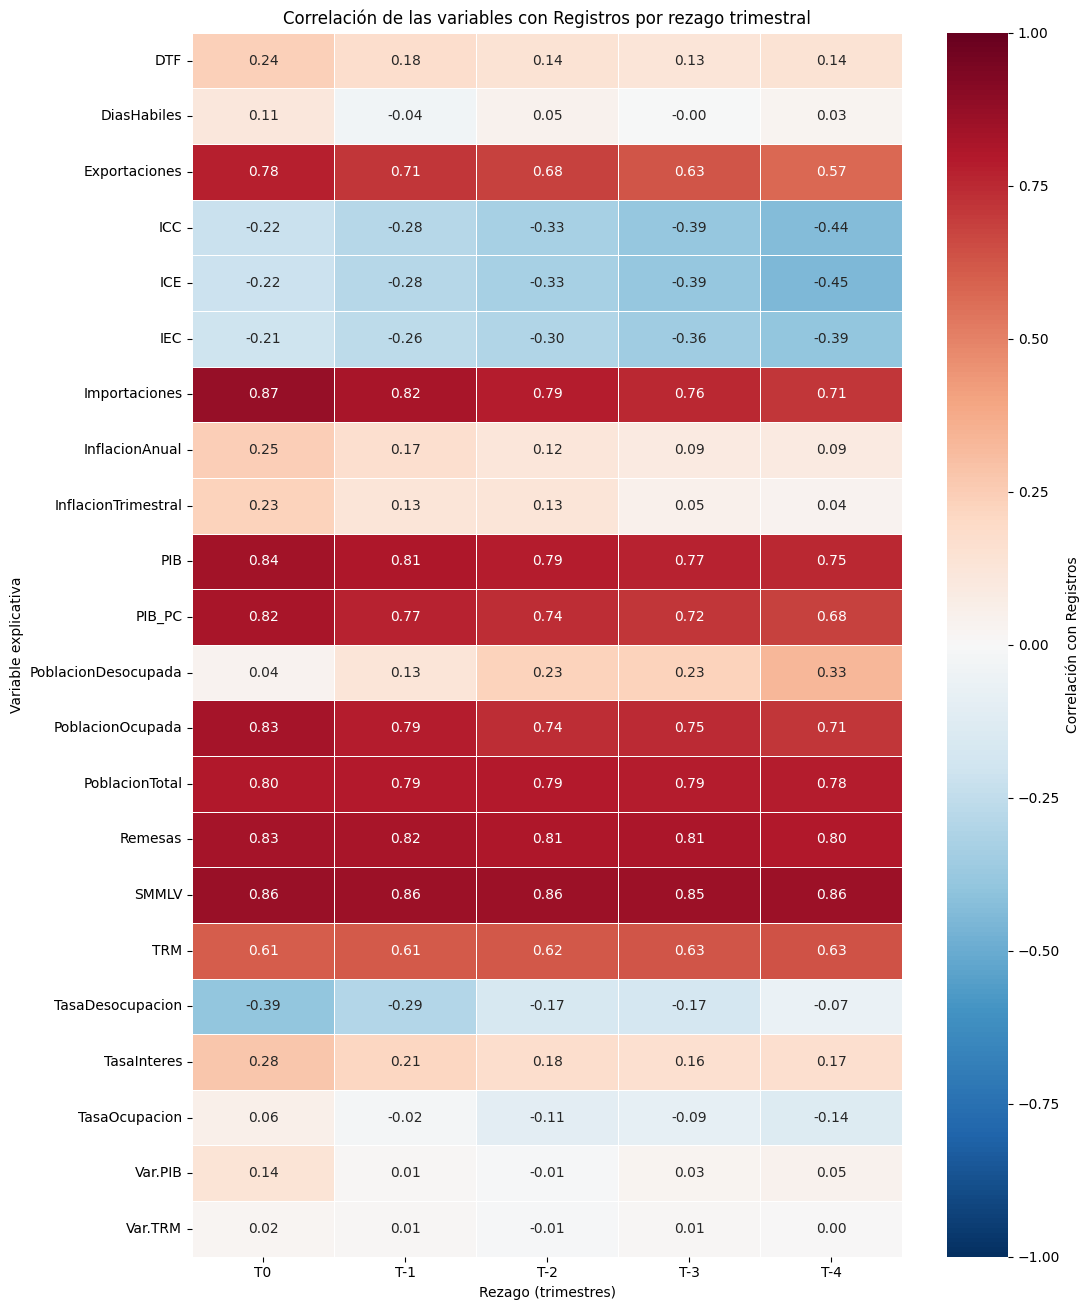

In [51]:
# Organizar los resultados en una matriz
mapa_rezagos = tabla_rezagos.pivot(
    index="Variable",
    columns="Rezago_trimestrales",
    values="Correlacion"
)

# Ordenar columnas de 0 a 4 trimestres
mapa_rezagos = mapa_rezagos.reindex(
    columns=[0, 1, 2, 3, 4]
)

# Graficar
plt.figure(figsize=(11, max(5, len(mapa_rezagos) * 0.6)))

sns.heatmap(
    mapa_rezagos,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Correlación con Registros"}
)

plt.title("Correlación de las variables con Registros por rezago trimestral")
plt.xlabel("Rezago (trimestres)")
plt.ylabel("Variable explicativa")
plt.xticks(
    ticks=[i + 0.5 for i in range(5)],
    labels=["T0", "T-1", "T-2", "T-3", "T-4"],
    rotation=0
)

plt.tight_layout()
plt.show()

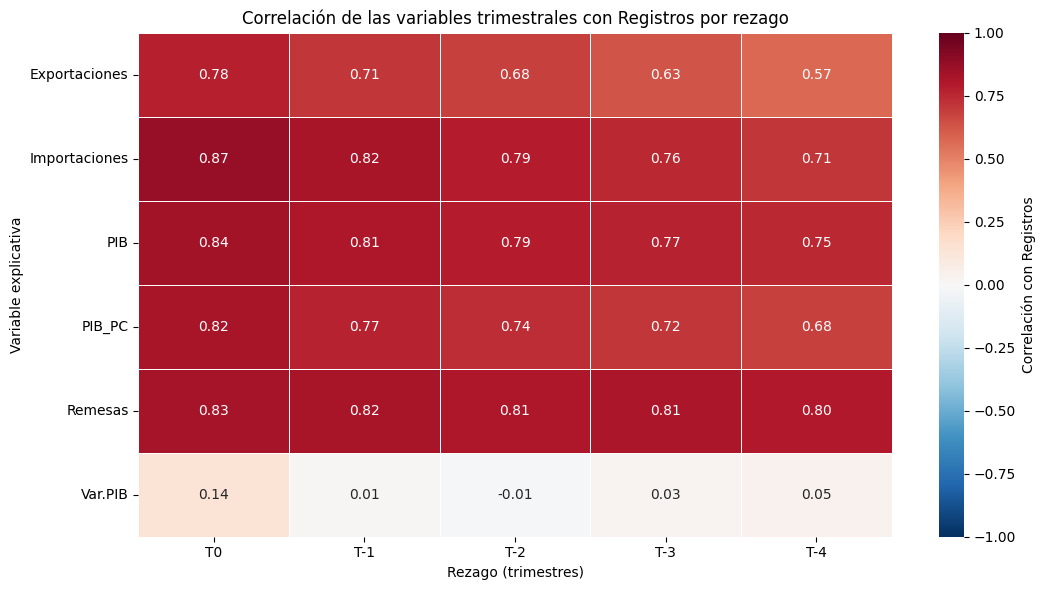

In [54]:
# Ordenar por fecha
df_datamercado = df_datamarket_trim.sort_values("FechaFin").copy()

# Seleccionar únicamente las variables trimestrales explicativas
variables_explicativas = variables_trimestrales

# Evaluar rezagos trimestrales
rezagos = [0, 1, 2, 3, 4]

resultados = []

for variable in variables_explicativas:
    for rezago in rezagos:

        correlacion = df_datamercado["Registros"].corr(
            df_datamercado[variable].shift(rezago)
        )

        resultados.append({
            "Variable": variable,
            "Rezago_trimestrales": rezago,
            "Correlacion": correlacion
        })

tabla_rezagos = pd.DataFrame(resultados)

# Mostrar resultados ordenados por correlación absoluta
#print(
#    tabla_rezagos.sort_values(
#       "Correlacion",
#       key=lambda x: x.abs(),
#        ascending=False
#    ).to_string(index=False)
#)

# Organizar los resultados en una matriz
mapa_rezagos = tabla_rezagos.pivot(
    index="Variable",
    columns="Rezago_trimestrales",
    values="Correlacion"
)

# Ordenar columnas de 0 a 4 trimestres
mapa_rezagos = mapa_rezagos.reindex(
    columns=[0, 1, 2, 3, 4]
)

# Graficar
plt.figure(figsize=(11, 6))

sns.heatmap(
    mapa_rezagos,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Correlación con Registros"}
)

plt.title("Correlación de las variables trimestrales con Registros por rezago")
plt.xlabel("Rezago (trimestres)")
plt.ylabel("Variable explicativa")

plt.xticks(
    ticks=[i + 0.5 for i in range(5)],
    labels=["T0", "T-1", "T-2", "T-3", "T-4"],
    rotation=0
)

plt.tight_layout()
plt.show()

Prueba con PIB sin desestacionalizar

In [92]:
#Dataset Trimestral
df_datamarket_trimV2 = pd.read_excel("Data - Mercado.xlsx", sheet_name="DataTrimestral_V2")

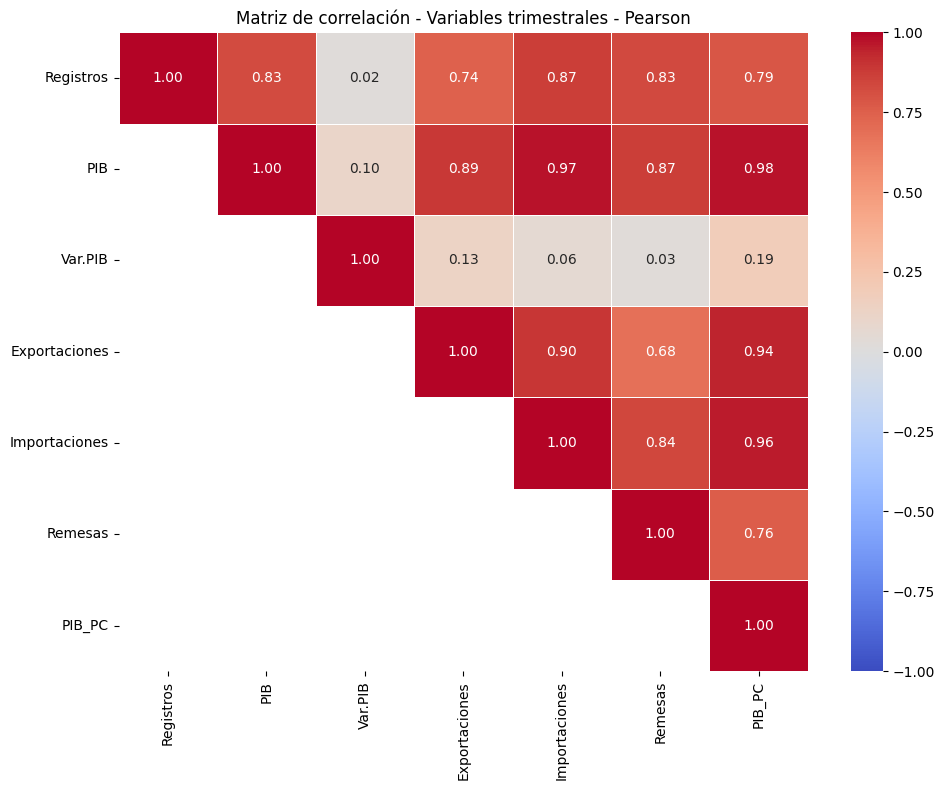

In [93]:
variables_trimestrales = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas",
    "PIB_PC"
]

# Seleccionar variables trimestrales + variable objetivo
variables_corr = ["Registros"] + variables_trimestrales

# Seleccionar únicamente las columnas de interés
datos_corr = df_datamarket_trimV2[variables_corr]

# Calcular la matriz de correlación de Pearson
matriz_corr = datos_corr.corr(method="pearson")

# Crear máscara para ocultar el triángulo inferior
mascara = np.tril(
    np.ones_like(matriz_corr, dtype=bool),
    k=-1
)

# Visualizar la matriz
plt.figure(figsize=(10, 8))

sns.heatmap(
    matriz_corr,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Matriz de correlación - Variables trimestrales - Pearson")
plt.tight_layout()
plt.show()

##Preparación de los Datos

Se combinan los dos datasets mensual y trimestral expandiendo las variables trimestrales a nivel de mes, repitiendo su valor.

In [74]:
# Variables trimestrales que se replicarán
variables_trimestrales = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas",
    "PIB_PC"
]

# Crear una copia del dataset trimestral
trim_expandido = df_datamarket_trim[
    ["FechaInicio", "FechaFin"] + variables_trimestrales
].copy()

# Generar los tres meses de cada trimestre
trim_expandido["Fecha"] = trim_expandido.apply(
    lambda fila: pd.date_range(
        start=fila["FechaInicio"],
        end=fila["FechaFin"],
        freq="MS"          # Inicio de cada mes
    ),
    axis=1
)

# Expandir una fila por cada mes
trim_expandido = trim_expandido.explode("Fecha")

# Conservar solo la fecha mensual y las variables trimestrales
trim_expandido = trim_expandido[
    ["Fecha"] + variables_trimestrales
].reset_index(drop=True)

# Unir con el dataset mensual
df_datamarket = df_datamarket_men.merge(
    trim_expandido,
    on="Fecha",
    how="left"
)

In [75]:
df_datamarket.head()

,Fecha,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,TRM,Var.TRM,TasaInteres,...,SMMLV,ICC,IEC,ICE,PIB,Var.PIB,Exportaciones,Importaciones,Remesas,PIB_PC
0,2005-01-01,11666,40318.940,16059.539,2455.597,0.569725,0.132626,2362.96,NaN,0.065,...,426000,0.193,0.266,0.083,126088.657004,NaN,21334.353184,18667.177575,731.13,312.433757
1,2005-02-01,12543,40358.098,16023.387,2629.476,0.567561,0.140969,2340.49,-0.009509,0.065,...,426000,0.139,0.189,0.065,126088.657004,NaN,21334.353184,18667.177575,731.13,312.433757
2,2005-03-01,13790,40393.737,16168.666,2406.260,0.571899,0.129543,2353.71,0.005648,0.065,...,426000,0.096,0.128,0.048,126088.657004,NaN,21334.353184,18667.177575,731.13,312.433757
3,2005-04-01,13569,40433.355,16346.018,2233.329,0.577268,0.120205,2350.01,-0.001572,0.065,...,426000,0.133,0.169,0.080,128906.474678,0.022348,22346.501950,19696.555294,803.26,318.501879
4,2005-05-01,15241,40472.262,16375.551,2337.372,0.577425,0.124907,2339.22,-0.004591,0.065,...,426000,0.141,0.147,0.130,128906.474678,0.022348,22346.501950,19696.555294,803.26,318.501879


In [76]:
# Exportaciones per cápita (pesos por persona)
df_datamarket["Exportaciones_PC"] = (
    (df_datamarket["Exportaciones"] * 100000) /
    (df_datamarket["PoblacionTotal"] * 1000)
)

# Importaciones per cápita (pesos por persona)
df_datamarket["Importaciones_PC"] = (
    (df_datamarket["Importaciones"] * 100000) /
    (df_datamarket["PoblacionTotal"] * 1000)
)


In [77]:
# Registros por cada 100 habitantes
df_datamarket["Registros_PC"] = (
    df_datamarket["Registros"] /
    (df_datamarket["PoblacionTotal"] * 1000)
) * 100

df_datamarket.head()

,Fecha,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,TRM,Var.TRM,TasaInteres,...,ICE,PIB,Var.PIB,Exportaciones,Importaciones,Remesas,PIB_PC,Exportaciones_PC,Importaciones_PC,Registros_PC
0,2005-01-01,11666,40318.940,16059.539,2455.597,0.569725,0.132626,2362.96,NaN,0.065,...,0.083,126088.657004,NaN,21334.353184,18667.177575,731.13,312.433757,52.913973,46.298781,0.028934
1,2005-02-01,12543,40358.098,16023.387,2629.476,0.567561,0.140969,2340.49,-0.009509,0.065,...,0.065,126088.657004,NaN,21334.353184,18667.177575,731.13,312.433757,52.862633,46.253859,0.031079
2,2005-03-01,13790,40393.737,16168.666,2406.260,0.571899,0.129543,2353.71,0.005648,0.065,...,0.048,126088.657004,NaN,21334.353184,18667.177575,731.13,312.433757,52.815993,46.213049,0.034139
3,2005-04-01,13569,40433.355,16346.018,2233.329,0.577268,0.120205,2350.01,-0.001572,0.065,...,0.080,128906.474678,0.022348,22346.501950,19696.555294,803.26,318.501879,55.267494,48.713631,0.033559
4,2005-05-01,15241,40472.262,16375.551,2337.372,0.577425,0.124907,2339.22,-0.004591,0.065,...,0.130,128906.474678,0.022348,22346.501950,19696.555294,803.26,318.501879,55.214364,48.666801,0.037658


In [78]:
# Columnas que deseas eliminar
columnas_eliminar = [
    "Registros",
    "Exportaciones",
    "Importaciones",
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "DTF"
]

# Eliminar columnas
df_datamarket = df_datamarket.drop(columns=columnas_eliminar)

# Verificar resultado
display(df_datamarket.head())

,Fecha,TasaDesocupacion,TRM,Var.TRM,TasaInteres,InflacionAnual,InflacionMensual,DiasHabiles,SMMLV,ICC,IEC,ICE,PIB,Var.PIB,Remesas,PIB_PC,Exportaciones_PC,Importaciones_PC,Registros_PC
0,2005-01-01,0.132626,2362.96,NaN,0.065,0.0543,0.0082,24,426000,0.193,0.266,0.083,126088.657004,NaN,731.13,312.433757,52.913973,46.298781,0.028934
1,2005-02-01,0.140969,2340.49,-0.009509,0.065,0.0525,0.0102,24,426000,0.139,0.189,0.065,126088.657004,NaN,731.13,312.433757,52.862633,46.253859,0.031079
2,2005-03-01,0.129543,2353.71,0.005648,0.065,0.0503,0.0077,24,426000,0.096,0.128,0.048,126088.657004,NaN,731.13,312.433757,52.815993,46.213049,0.034139
3,2005-04-01,0.120205,2350.01,-0.001572,0.065,0.0501,0.0044,26,426000,0.133,0.169,0.080,128906.474678,0.022348,803.26,318.501879,55.267494,48.713631,0.033559
4,2005-05-01,0.124907,2339.22,-0.004591,0.065,0.0504,0.0041,24,426000,0.141,0.147,0.130,128906.474678,0.022348,803.26,318.501879,55.214364,48.666801,0.037658


Dado que el salario mínimo va creciendo por la inflación, el objetivo es poder mostrarlo en términos que signifiquen poder adquisitivo. Para esto se hará uso del IPC para calcular el salario real con base en el salario nominal.

In [82]:
#Dataset Mensual
df_IPC = pd.read_excel("Data - Mercado.xlsx", sheet_name="IPC")

In [87]:
# Preparar dataset IPC
df_IPC["Fecha"] = pd.to_datetime(df_IPC["Fecha"])
df_datamarket["Fecha"] = pd.to_datetime(df_datamarket["Fecha"])

# Unir IPC al dataset principal
df_datamarket = df_datamarket.merge(
    df_IPC[["Fecha", "IPC"]],
    on="Fecha",
    how="left"
)
df_datamarket.head()

,Fecha,TasaDesocupacion,TRM,Var.TRM,TasaInteres,InflacionAnual,InflacionMensual,DiasHabiles,SMMLV,ICC,...,PIB,Var.PIB,Remesas,PIB_PC,Exportaciones_PC,Importaciones_PC,Registros_PC,IPC_x,IPC_y,IPC
0,2005-01-01,0.132626,2362.96,NaN,0.065,0.0543,0.0082,24,426000,0.193,...,126088.657004,NaN,731.13,312.433757,52.913973,46.298781,0.028934,56.45,56.45,56.45
1,2005-02-01,0.140969,2340.49,-0.009509,0.065,0.0525,0.0102,24,426000,0.139,...,126088.657004,NaN,731.13,312.433757,52.862633,46.253859,0.031079,57.02,57.02,57.02
2,2005-03-01,0.129543,2353.71,0.005648,0.065,0.0503,0.0077,24,426000,0.096,...,126088.657004,NaN,731.13,312.433757,52.815993,46.213049,0.034139,57.46,57.46,57.46
3,2005-04-01,0.120205,2350.01,-0.001572,0.065,0.0501,0.0044,26,426000,0.133,...,128906.474678,0.022348,803.26,318.501879,55.267494,48.713631,0.033559,57.72,57.72,57.72
4,2005-05-01,0.124907,2339.22,-0.004591,0.065,0.0504,0.0041,24,426000,0.141,...,128906.474678,0.022348,803.26,318.501879,55.214364,48.666801,0.037658,57.95,57.95,57.95


In [88]:
# Salario mostrando poder adquisitivo
df_datamarket["SMMLV_PA"] = (
    df_datamarket["SMMLV"] /
    (df_datamarket["IPC"])
) * 100

df_datamarket.head()

,Fecha,TasaDesocupacion,TRM,Var.TRM,TasaInteres,InflacionAnual,InflacionMensual,DiasHabiles,SMMLV,ICC,...,Var.PIB,Remesas,PIB_PC,Exportaciones_PC,Importaciones_PC,Registros_PC,IPC_x,IPC_y,IPC,SMMLV_PA
0,2005-01-01,0.132626,2362.96,NaN,0.065,0.0543,0.0082,24,426000,0.193,...,NaN,731.13,312.433757,52.913973,46.298781,0.028934,56.45,56.45,56.45,754650.132861
1,2005-02-01,0.140969,2340.49,-0.009509,0.065,0.0525,0.0102,24,426000,0.139,...,NaN,731.13,312.433757,52.862633,46.253859,0.031079,57.02,57.02,57.02,747106.278499
2,2005-03-01,0.129543,2353.71,0.005648,0.065,0.0503,0.0077,24,426000,0.096,...,NaN,731.13,312.433757,52.815993,46.213049,0.034139,57.46,57.46,57.46,741385.311521
3,2005-04-01,0.120205,2350.01,-0.001572,0.065,0.0501,0.0044,26,426000,0.133,...,0.022348,803.26,318.501879,55.267494,48.713631,0.033559,57.72,57.72,57.72,738045.738046
4,2005-05-01,0.124907,2339.22,-0.004591,0.065,0.0504,0.0041,24,426000,0.141,...,0.022348,803.26,318.501879,55.214364,48.666801,0.037658,57.95,57.95,57.95,735116.479724


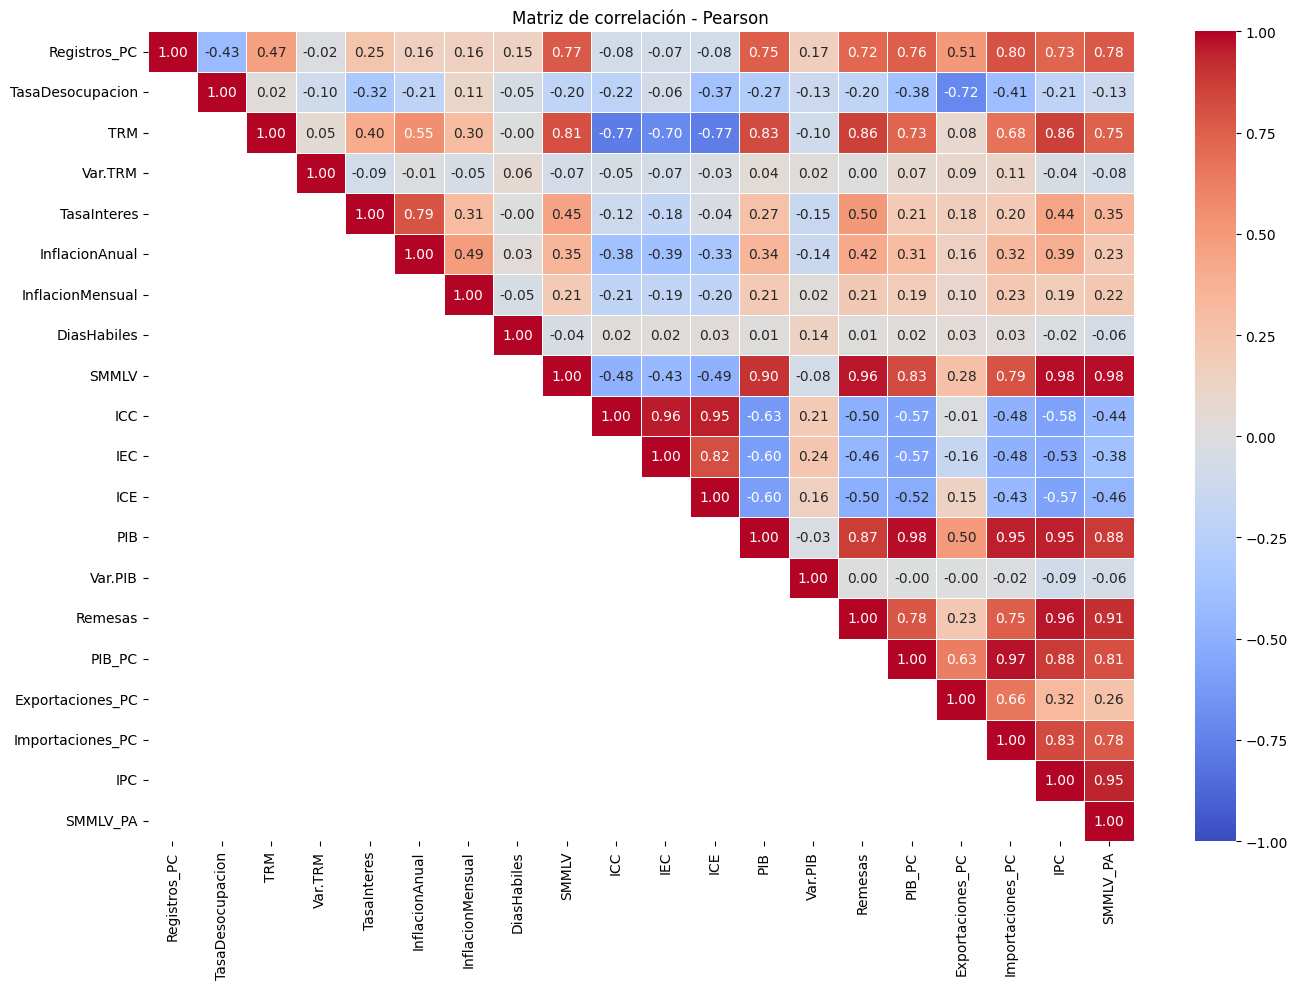

In [91]:
# Seleccionar variables numéricas
variables = df_datamarket.select_dtypes(include="number")

# Calcular matriz de correlación de Pearson
matriz_corr = variables.corr(method="pearson")

# Colocar Registros_PC de primero, conservando el orden de las demás
orden = ["Registros_PC"] + [
    col for col in matriz_corr.columns
    if col != "Registros_PC"
]

matriz_corr = matriz_corr.loc[orden, orden]

# Crear máscara para ocultar el triángulo inferior
mascara = np.tril(
    np.ones_like(matriz_corr, dtype=bool),
    k=-1
)

# Visualizar la matriz
plt.figure(figsize=(14, 10))

sns.heatmap(
    matriz_corr,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Matriz de correlación - Pearson")
plt.tight_layout()
plt.show()

##Modelación

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")

In [ ]:
variables_mensuales = [
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "TasaDesocupacion",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "DTF",
    "InflacionAnual",
    "InflacionMensual",
    "DiasHabiles",
    "SMMLV",
    "ICC",
    "IEC",
    "ICE"
]

variables_trimestrales = [
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "TasaDesocupacion",
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "DTF",
    "InflacionAnual",
    "InflacionTrimestral",
    "DiasHabiles",
    "Remesas",
    "PIB_PC",
    "SMMLV",
    "ICC",
    "IEC",
    "ICE"
]

In [ ]:
# Copias de trabajo: no modificamos los DataFrames originales
datos_objetivo = objetivo[["Fecha", "Registros"]].copy()
datos_mensuales = df_datamarket_men.copy()

datos_objetivo["Fecha"] = pd.to_datetime(datos_objetivo["Fecha"])
datos_mensuales["Fecha"] = pd.to_datetime(datos_mensuales["Fecha"])

datos_objetivo["Periodo"] = datos_objetivo["Fecha"].dt.to_period("M")
datos_mensuales["Periodo"] = datos_mensuales["Fecha"].dt.to_period("M")

# Comprobar que exista una observación por mes
assert not datos_objetivo["Periodo"].duplicated().any(), (
    "La variable objetivo tiene meses duplicados."
)

assert not datos_mensuales["Periodo"].duplicated().any(), (
    "Los predictores mensuales tienen meses duplicados."
)

predictores_men = [
    col for col in variables_mensuales
    if col in datos_mensuales.columns
]

base_mensual_rf = datos_objetivo[
    ["Periodo", "Registros"]
].merge(
    datos_mensuales[["Periodo"] + predictores_men],
    on="Periodo",
    how="left",
    validate="one_to_one"
).sort_values("Periodo").reset_index(drop=True)

print("Observaciones:", len(base_mensual_rf))
print("Predictores disponibles:", predictores_men)
print("Periodo inicial:", base_mensual_rf["Periodo"].min())
print("Periodo final:", base_mensual_rf["Periodo"].max())

Observaciones: 259
Predictores disponibles: ['PoblacionTotal', 'PoblacionOcupada', 'PoblacionDesocupada', 'TasaOcupacion', 'TasaDesocupacion', 'TRM', 'Var.TRM', 'TasaInteres', 'DTF', 'InflacionAnual', 'InflacionMensual', 'DiasHabiles', 'SMMLV', 'ICC', 'IEC', 'ICE']
Periodo inicial: 2005-01
Periodo final: 2026-07


In [ ]:
datos_registros_trim = objetivo[["Fecha", "Registros"]].copy()
datos_trim = df_datamarket_trim.copy()

datos_registros_trim["Fecha"] = pd.to_datetime(
    datos_registros_trim["Fecha"]
)
datos_trim["FechaFin"] = pd.to_datetime(datos_trim["FechaFin"])

datos_registros_trim["Periodo"] = (
    datos_registros_trim["Fecha"].dt.to_period("Q")
)

datos_trim["Periodo"] = (
    datos_trim["FechaFin"].dt.to_period("Q")
)

registros_trim = (
    datos_registros_trim
    .groupby("Periodo", as_index=False)
    .agg(Registros=("Registros", "sum"))
)

assert not datos_trim["Periodo"].duplicated().any(), (
    "Los predictores trimestrales tienen trimestres duplicados."
)

predictores_trim = [
    col for col in variables_trimestrales
    if col in datos_trim.columns
]

base_trimestral_rf = registros_trim.merge(
    datos_trim[["Periodo"] + predictores_trim],
    on="Periodo",
    how="left",
    validate="one_to_one"
).sort_values("Periodo").reset_index(drop=True)

print("Observaciones:", len(base_trimestral_rf))
print("Predictores disponibles:", predictores_trim)
print("Periodo inicial:", base_trimestral_rf["Periodo"].min())
print("Periodo final:", base_trimestral_rf["Periodo"].max())

Observaciones: 87
Predictores disponibles: ['PoblacionTotal', 'PoblacionOcupada', 'PoblacionDesocupada', 'TasaOcupacion', 'TasaDesocupacion', 'PIB', 'Var.PIB', 'Exportaciones', 'Importaciones', 'TRM', 'Var.TRM', 'TasaInteres', 'DTF', 'InflacionAnual', 'InflacionTrimestral', 'DiasHabiles', 'Remesas', 'PIB_PC', 'SMMLV', 'ICC', 'IEC', 'ICE']
Periodo inicial: 2005Q1
Periodo final: 2026Q3


In [ ]:

def entrenar_random_forest(base, predictores, nombre_modelo,
                           proporcion_test=0.20):

    datos = base.copy().sort_values("Periodo").reset_index(drop=True)

    X = datos[predictores].apply(pd.to_numeric, errors="coerce")
    y = pd.to_numeric(datos["Registros"], errors="coerce")

    # Excluir observaciones sin variable objetivo
    validos = y.notna()

    X = X.loc[validos].reset_index(drop=True)
    y = y.loc[validos].reset_index(drop=True)
    periodos = datos.loc[validos, "Periodo"].reset_index(drop=True)

    # Eliminar variables que no tienen ningún dato
    X = X.dropna(axis=1, how="all")

    if len(X) < 20:
        raise ValueError(
            f"{nombre_modelo}: hay menos de 20 observaciones. "
            "Revisa el tamaño de la muestra."
        )

    if X.shape[1] == 0:
        raise ValueError("No hay variables predictoras disponibles.")

    # División cronológica: no mezclar el orden temporal
    punto_corte = int(len(X) * (1 - proporcion_test))

    X_train = X.iloc[:punto_corte]
    X_test = X.iloc[punto_corte:]

    y_train = y.iloc[:punto_corte]
    y_test = y.iloc[punto_corte:]

    # Modelo Random Forest
    modelo = Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("rf", RandomForestRegressor(
            n_estimators=500,
            max_features=1.0,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ])

    modelo.fit(X_train, y_train)

    predicciones = modelo.predict(X_test)

    # Métricas de desempeño
    mae = mean_absolute_error(y_test, predicciones)
    rmse = np.sqrt(mean_squared_error(y_test, predicciones))

    # MAPE: excluir valores reales iguales a cero
    mascara_mape = y_test != 0

    if mascara_mape.any():
        mape = np.mean(
            np.abs(
                (y_test[mascara_mape].to_numpy()
                 - predicciones[mascara_mape.to_numpy()])
                / y_test[mascara_mape].to_numpy()
            )
        ) * 100
    else:
        mape = np.nan

    metricas = pd.DataFrame([{
        "Modelo": nombre_modelo,
        "Observaciones entrenamiento": len(X_train),
        "Observaciones prueba": len(X_test),
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }])

    # Importancia propia del Random Forest
    importancias_rf = pd.Series(
        modelo.named_steps["rf"].feature_importances_,
        index=X.columns,
        name="Importancia_RF"
    )

    # Importancia por permutación sobre el conjunto de prueba
    permutacion = permutation_importance(
        modelo,
        X_test,
        y_test,
        scoring="neg_mean_absolute_error",
        n_repeats=20,
        random_state=42,
        n_jobs=-1
    )

    importancias_perm = pd.DataFrame({
        "Variable": X.columns,
        "Importancia_permutacion": permutacion.importances_mean,
        "Desviacion_importancia": permutacion.importances_std
    })

    importancias_perm = importancias_perm.merge(
        importancias_rf.rename_axis("Variable").reset_index(),
        on="Variable",
        how="left"
    )

    importancias_perm = importancias_perm.sort_values(
        "Importancia_permutacion",
        ascending=False
    ).reset_index(drop=True)

    # Resultados de las predicciones del conjunto de prueba
    resultados_test = pd.DataFrame({
        "Periodo": periodos.iloc[punto_corte:].reset_index(drop=True),
        "Real": y_test.reset_index(drop=True),
        "Predicho": predicciones
    })

    return modelo, metricas, importancias_perm, resultados_test


In [ ]:
modelo_mensual, metricas_mensual, importancia_mensual, test_mensual = (
    entrenar_random_forest(
        base=base_mensual_rf,
        predictores=predictores_men,
        nombre_modelo="Random Forest mensual"
    )
)

display(metricas_mensual)
display(importancia_mensual)

,Modelo,Observaciones entrenamiento,Observaciones prueba,MAE,RMSE,MAPE (%)
0,Random Forest mensual,207,52,17055.996856,22505.479152,20.464036


,Variable,Importancia_permutacion,Desviacion_importancia,Importancia_RF
0,TasaOcupacion,6.248757e+01,4.155994e+01,0.013023
1,PoblacionDesocupada,1.029990e+01,1.026180e+01,0.004515
2,Var.TRM,7.587131e+00,1.966935e+01,0.014660
3,DiasHabiles,6.755483e+00,3.649852e+01,0.016282
4,PoblacionOcupada,1.873637e-01,2.486195e-01,0.476856
5,PoblacionTotal,1.273293e-12,1.735205e-12,0.278420
6,SMMLV,1.091394e-12,1.667131e-12,0.025279
7,TasaInteres,-2.653453e-01,4.145714e-01,0.007095
8,DTF,-2.997485e-01,3.926647e-01,0.054702
9,TasaDesocupacion,-9.519432e-01,2.552867e+00,0.004918


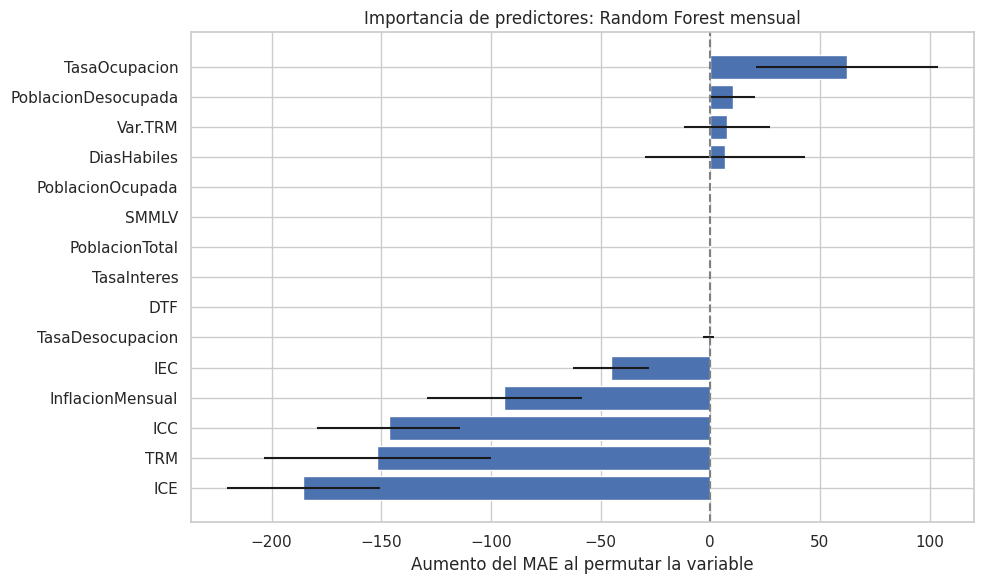

In [ ]:
top_mensual = importancia_mensual.head(15).sort_values(
    "Importancia_permutacion"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_mensual["Variable"],
    top_mensual["Importancia_permutacion"],
    xerr=top_mensual["Desviacion_importancia"]
)

plt.axvline(0, color="gray", linestyle="--")
plt.xlabel("Aumento del MAE al permutar la variable")
plt.title("Importancia de predictores: Random Forest mensual")
plt.tight_layout()
plt.show()

In [ ]:
modelo_trimestral, metricas_trimestral, importancia_trimestral, test_trimestral = (
    entrenar_random_forest(
        base=base_trimestral_rf,
        predictores=predictores_trim,
        nombre_modelo="Random Forest trimestral"
    )
)

display(metricas_trimestral)
display(importancia_trimestral)

,Modelo,Observaciones entrenamiento,Observaciones prueba,MAE,RMSE,MAPE (%)
0,Random Forest trimestral,69,18,49281.998305,71899.784852,18.282161


,Variable,Importancia_permutacion,Desviacion_importancia,Importancia_RF
0,Importaciones,815.168115,345.928551,0.261596
1,PIB,785.516929,372.115189,0.078565
2,PIB_PC,673.193693,324.684316,0.272926
3,PoblacionTotal,595.482031,278.392752,0.067640
4,TRM,285.603918,571.318579,0.022596
5,Remesas,178.214964,107.090768,0.009536
6,IEC,175.911612,80.257725,0.012611
7,ICC,90.830108,58.920446,0.022081
8,ICE,48.107822,36.422523,0.023755
9,SMMLV,47.536694,34.620483,0.040896


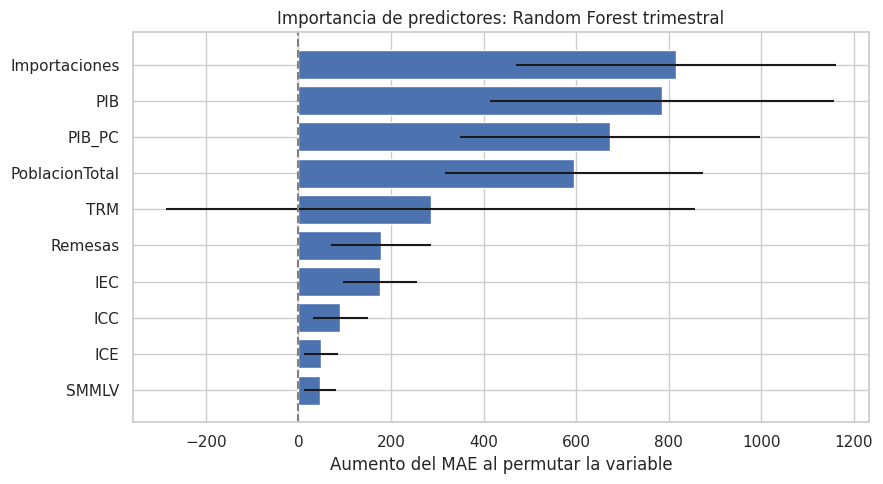

In [ ]:
top_trimestral = importancia_trimestral.sort_values(
    "Importancia_permutacion"
).tail(10)

plt.figure(figsize=(9, 5))

plt.barh(
    top_trimestral["Variable"],
    top_trimestral["Importancia_permutacion"],
    xerr=top_trimestral["Desviacion_importancia"]
)

plt.axvline(0, color="gray", linestyle="--")
plt.xlabel("Aumento del MAE al permutar la variable")
plt.title("Importancia de predictores: Random Forest trimestral")
plt.tight_layout()
plt.show()

In [ ]:
comparacion_modelos = pd.concat(
    [metricas_mensual, metricas_trimestral],
    ignore_index=True
)

display(comparacion_modelos)

,Modelo,Observaciones entrenamiento,Observaciones prueba,MAE,RMSE,MAPE (%)
0,Random Forest mensual,207,52,17055.996856,22505.479152,20.464036
1,Random Forest trimestral,69,18,49281.998305,71899.784852,18.282161


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Copiar resultados de prueba
mensual = test_mensual.copy()
trimestral = test_trimestral.copy()

# Convertir los periodos a fechas mensuales
mensual["Periodo"] = pd.PeriodIndex(
    mensual["Periodo"], freq="M"
)

trimestral["Periodo"] = pd.PeriodIndex(
    trimestral["Periodo"], freq="Q"
)

# Agregar las predicciones mensuales por trimestre
mensual["Trimestre"] = mensual["Periodo"].dt.asfreq("Q")

mensual_trim = (
    mensual.groupby("Trimestre")
    .agg(
        Real_mensual=("Real", "sum"),
        Predicho_mensual=("Predicho", "sum"),
        Meses=("Periodo", "nunique")
    )
    .reset_index()
)

# Conservar únicamente trimestres completos de prueba
mensual_trim = mensual_trim[mensual_trim["Meses"] == 3].copy()

# Renombrar periodo trimestral del modelo trimestral
trimestral = trimestral.rename(
    columns={
        "Periodo": "Trimestre",
        "Real": "Real_trimestral",
        "Predicho": "Predicho_trimestral"
    }
)

# Unir por los mismos trimestres
comparacion = mensual_trim.merge(
    trimestral[
        ["Trimestre", "Real_trimestral", "Predicho_trimestral"]
    ],
    on="Trimestre",
    how="inner"
)

# Comprobar que ambos modelos usan la misma variable objetivo
comparacion["Diferencia_reales"] = (
    comparacion["Real_mensual"]
    - comparacion["Real_trimestral"]
)

display(comparacion)

,Trimestre,Real_mensual,Predicho_mensual,Meses,Real_trimestral,Predicho_trimestral,Diferencia_reales
0,2022Q2,203659,210806.344374,3,203659,181853.245113,0
1,2022Q3,210392,212801.064145,3,210392,182190.573030,0
2,2022Q4,178152,213351.194210,3,178152,181893.208448,0
3,2023Q1,179331,210473.893025,3,179331,180744.313125,0
4,2023Q2,163393,211805.219259,3,163393,180234.853148,0
5,2023Q3,168583,211843.379610,3,168583,179309.686863,0
6,2023Q4,169217,211010.407322,3,169217,180179.399484,0
7,2024Q1,179259,208854.381517,3,179259,181192.448998,0
8,2024Q2,192420,210186.860127,3,192420,180464.759179,0
9,2024Q3,212754,209131.941014,3,212754,180950.864932,0


In [ ]:
def calcular_metricas(y_real, y_predicho, nombre_modelo):
    y_real = np.asarray(y_real, dtype=float)
    y_predicho = np.asarray(y_predicho, dtype=float)

    mascara = y_real != 0

    mape = (
        np.mean(
            np.abs(
                (y_real[mascara] - y_predicho[mascara])
                / y_real[mascara]
            )
        ) * 100
        if mascara.any()
        else np.nan
    )

    return {
        "Modelo": nombre_modelo,
        "Trimestres evaluados": len(y_real),
        "MAE trimestral": mean_absolute_error(y_real, y_predicho),
        "RMSE trimestral": np.sqrt(
            mean_squared_error(y_real, y_predicho)
        ),
        "MAPE (%)": mape
    }


metricas_comparables = pd.DataFrame([
    calcular_metricas(
        comparacion["Real_mensual"],
        comparacion["Predicho_mensual"],
        "Random Forest mensual agregado a trimestre"
    ),
    calcular_metricas(
        comparacion["Real_trimestral"],
        comparacion["Predicho_trimestral"],
        "Random Forest trimestral"
    )
])

display(metricas_comparables.round(3))

,Modelo,Trimestres evaluados,MAE trimestral,RMSE trimestral,MAPE (%)
0,Random Forest mensual agregado a trimestre,17,47390.898,60926.019,19.441
1,Random Forest trimestral,17,51695.250,73957.162,18.990


##Evaluación